# Microsoft Azure Predictive Maintenance

Predictive maintenance research using the Azure PdM dataset. Includes exploratory data analysis, time-based feature engineering, CatBoost model training, hyperparameter optimization, and evaluation of equipment failure predictions within a 24-hour horizon

## Set up Environment

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import optuna

from catboost import CatBoostClassifier, Pool
from sklearn.metrics import classification_report, f1_score
from sklearn.metrics import confusion_matrix, accuracy_score


pd.set_option('display.max_rows', 10)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 20)

sns.set_theme(
    style='whitegrid',
    palette='viridis',
    context='notebook',
    rc={
        'figure.dpi': 120,
        'axes.titlesize': 9,
        'axes.labelsize': 7,
        'axes.grid': True,
        'grid.color': 'gray',
        'grid.linestyle': '-',
        'grid.linewidth': 0.8,
        'grid.alpha': 0.2,
        'xtick.labelsize': 7,
        'ytick.labelsize': 7,
        'legend.frameon': False,
        'legend.fontsize': 8,
        'legend.title_fontsize': 9,
        'savefig.bbox': 'tight',
    }
)

%config InlineBackend.figure_format = 'retina'

## Data Acquisition and Analysis

Load telemetry, error logs, replacement records, failure events and machine metadata

In [2]:
# load data
telemetry = pd.read_csv('pdm/PdM_telemetry.csv', parse_dates=['datetime'])
errors = pd.read_csv('pdm/PdM_errors.csv', parse_dates=['datetime'])
maint = pd.read_csv('pdm/PdM_maint.csv', parse_dates=['datetime'])
failures = pd.read_csv('pdm/PdM_failures.csv', parse_dates=['datetime'])
machines = pd.read_csv('pdm/PdM_machines.csv')

### Telemetry Analysis

Examine sensor distributions and temporal patterns for machines to identify unusual values and potential differences between operating conditions

#### Data Quality

In [3]:
# sort telemetry and define sensor columns
telemetry = telemetry.sort_values(['machineID', 'datetime']).reset_index(drop=True)
sensors = ['volt', 'rotate', 'pressure', 'vibration']

# inspect raw telemetry data and sensor statistics
display(telemetry)
display(telemetry[sensors].describe().T)

,datetime,machineID,volt,rotate,pressure,vibration
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511
...,...,...,...,...,...,...
876095,2016-01-01 02:00:00,100,179.438162,395.222827,102.290715,50.771941
876096,2016-01-01 03:00:00,100,189.617555,446.207972,98.180607,35.123072
876097,2016-01-01 04:00:00,100,192.483414,447.816524,94.132837,48.314561
876098,2016-01-01 05:00:00,100,165.475310,413.771670,104.081073,44.835259


,count,mean,std,min,25%,50%,75%,max
volt,876100.0,170.777736,15.509114,97.333604,160.304927,170.607338,181.004493,255.124717
rotate,876100.0,446.605119,52.673886,138.432075,412.305714,447.558150,482.176600,695.020984
pressure,876100.0,100.858668,11.048679,51.237106,93.498181,100.425559,107.555231,185.951998
vibration,876100.0,40.385007,5.370361,14.877054,36.777299,40.237247,43.784938,76.791072


In [4]:
# count missing values and duplicate observations
quality_summary = pd.DataFrame({
    'count': {
        'observations': len(telemetry),
        'machines': telemetry['machineID'].nunique(),
        'duplicate_machine_ts': telemetry.duplicated(['machineID', 'datetime']).sum(),
        'missing_values': telemetry[['machineID', 'datetime', *sensors]].isna().sum().sum(),
        **{
            f'missing_{col}': telemetry[col].isna().sum()
            for col in ['machineID', 'datetime', *sensors]
        }
    }
})

display(quality_summary)

,count
observations,876100
machines,100
duplicate_machine_ts,0
missing_values,0
missing_machineID,0
missing_datetime,0
missing_volt,0
missing_rotate,0
missing_pressure,0
missing_vibration,0


In [5]:
# check sampling intervals separately for each machine
intervals = telemetry.groupby('machineID')['datetime'].diff()
interval_summary = intervals.value_counts(dropna=False).rename_axis('interval').to_frame('count')

display(interval_summary)

,count
interval,
0 days 01:00:00,876000
NaT,100


The 100 NaT values correspond to the first observation for each machine, where no preceding timestamp is available

In [6]:
# summarize temporal coverage and hourly grid gaps for each machine
machine_coverage = telemetry.groupby('machineID').agg(
    start_timestamp=('datetime', 'min'),
    end_timestamp=('datetime', 'max'),
    observations=('datetime', 'size'),
    unique_timestamps=('datetime', 'nunique'),
)

machine_coverage['expected_hourly_observations'] = (
    (machine_coverage['end_timestamp'] - machine_coverage['start_timestamp']) / pd.Timedelta(hours=1)
).astype('int64') + 1
machine_coverage['missing_hourly_timestamps'] = (
    machine_coverage['expected_hourly_observations'] - machine_coverage['unique_timestamps']
)

display(machine_coverage.reset_index())
display(machine_coverage.describe().T)

,machineID,start_timestamp,end_timestamp,observations,unique_timestamps,expected_hourly_observations,missing_hourly_timestamps
0,1,2015-01-01 06:00:00,2016-01-01 06:00:00,8761,8761,8761,0
1,2,2015-01-01 06:00:00,2016-01-01 06:00:00,8761,8761,8761,0
2,3,2015-01-01 06:00:00,2016-01-01 06:00:00,8761,8761,8761,0
3,4,2015-01-01 06:00:00,2016-01-01 06:00:00,8761,8761,8761,0
4,5,2015-01-01 06:00:00,2016-01-01 06:00:00,8761,8761,8761,0
...,...,...,...,...,...,...,...
95,96,2015-01-01 06:00:00,2016-01-01 06:00:00,8761,8761,8761,0
96,97,2015-01-01 06:00:00,2016-01-01 06:00:00,8761,8761,8761,0
97,98,2015-01-01 06:00:00,2016-01-01 06:00:00,8761,8761,8761,0
98,99,2015-01-01 06:00:00,2016-01-01 06:00:00,8761,8761,8761,0


,count,mean,min,25%,50%,75%,max,std
start_timestamp,100,2015-01-01 06:00:00,2015-01-01 06:00:00,2015-01-01 06:00:00,2015-01-01 06:00:00,2015-01-01 06:00:00,2015-01-01 06:00:00,NaN
end_timestamp,100,2016-01-01 06:00:00,2016-01-01 06:00:00,2016-01-01 06:00:00,2016-01-01 06:00:00,2016-01-01 06:00:00,2016-01-01 06:00:00,NaN
observations,100.0,8761.0,8761.0,8761.0,8761.0,8761.0,8761.0,0.0
unique_timestamps,100.0,8761.0,8761.0,8761.0,8761.0,8761.0,8761.0,0.0
expected_hourly_observations,100.0,8761.0,8761.0,8761.0,8761.0,8761.0,8761.0,0.0
missing_hourly_timestamps,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


All 100 machines have identical temporal coverage, spanning from January 1, 2015, to January 1, 2016, with 8,761 hourly observations per machine. No missing or duplicate timestamps were detected within the expected hourly grid

#### Individual Machine Telemetry

In [7]:
def plot_machine_telemetry(telemetry, machine_id, sensors):
    
    # select individual machine data
    data = telemetry.loc[telemetry['machineID'].eq(machine_id)].sort_values('datetime')
    if data.empty:
        raise ValueError(f'No telemetry for machine {machine_id}')

    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, layout='constrained')
    
    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(data['datetime'], data[sensor], linewidth=0.7, alpha=0.8)
        ax.set(title=f'{sensor.capitalize()}. Machine {machine_id}', ylabel='Sensor value')
    
    for ax in axes.flat[len(sensors):]:
        ax.set_visible(False)
    
    for ax in axes[-1]:
        ax.set_xlabel('Datetime')
        
    plt.show()

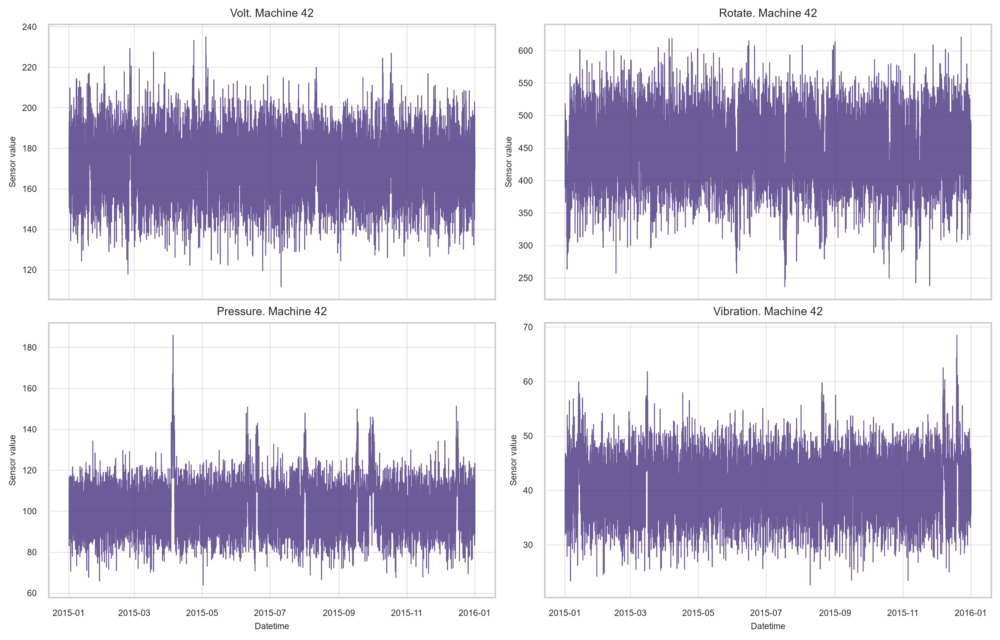

In [8]:
# inspect the temporal dynamics of a representative machine
plot_machine_telemetry(telemetry=telemetry, machine_id=42, sensors=sensors)

#### Machine Fleet Comparison

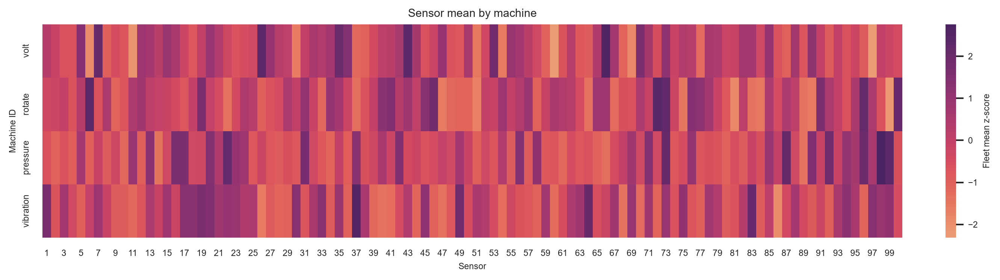

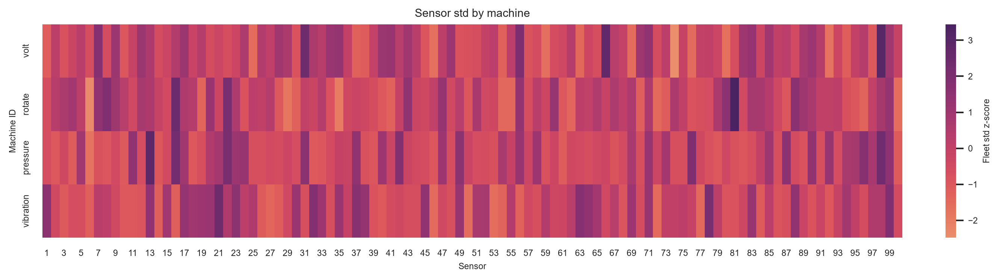

In [9]:
# compare sensor location and variability across all machines
fleet_summary = telemetry.groupby('machineID')[sensors].agg(['mean', 'std'])

for statistic in ['mean', 'std']:

    # standardize each sensor across machines
    values = fleet_summary.xs(statistic, axis=1, level=1)
    scaled = (values - values.mean()) / values.std(ddof=0).replace(0, np.nan)

    fig, ax = plt.subplots(figsize=(11, 3), layout='constrained')
    sns.heatmap(scaled.T, cmap='flare', center=0, ax=ax, cbar_kws={'label': f'Fleet {statistic} z-score'})
    ax.set(title=f'Sensor {statistic} by machine', xlabel='Sensor', ylabel='Machine ID')
    ax.tick_params(axis='x', rotation=0)
    ax.tick_params(axis='y', rotation=90)

    plt.show()

The heatmaps reveal differences in the mean values and variability of sensor measurements across the machine fleet. Most machines exhibit moderate deviations from the fleet averages, while some show relatively high or low values for individual parameters. No clear grouping of machines with similar sensor profiles is visually apparent. These differences may reflect individual equipment characteristics, operating conditions, or variations in technical condition

#### Sensor Distributions

In [10]:
# define selected-machine vs fleet distribution function
def plot_sensor_distribution(telemetry, machine_id, sensors, bins=40):

    mask = telemetry['machineID'].eq(machine_id)
    if not mask.any() or mask.all():
        raise ValueError(f'Selected machine {machine_id} or reference data is empty')

    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
    for ax, sensor in zip(axes.flat, sensors):
        
        selected = telemetry.loc[mask, sensor].dropna()
        reference = telemetry.loc[~mask, sensor].dropna()

        # use common bin edges for both distributions
        bin_edges = np.histogram_bin_edges(pd.concat([selected, reference]), bins=bins)

        sns.histplot(
            reference, bins=bin_edges, stat='density',
            color=sns.color_palette()[0], alpha=0.35,
            element='step', label='Other machines', ax=ax
        )
        sns.histplot(
            selected, bins=bin_edges, stat='density',
            color=sns.color_palette()[4], alpha=0.4,
            element='step', label=f'Machine {machine_id}', ax=ax
        )
        ax.set(
            title=sensor.capitalize(),
            xlabel='Sensor value',
            ylabel='Probability density'
        )
        ax.legend()

    fig.suptitle(f'Sensor distributions. Machine {machine_id}', fontsize=11)
    plt.show()

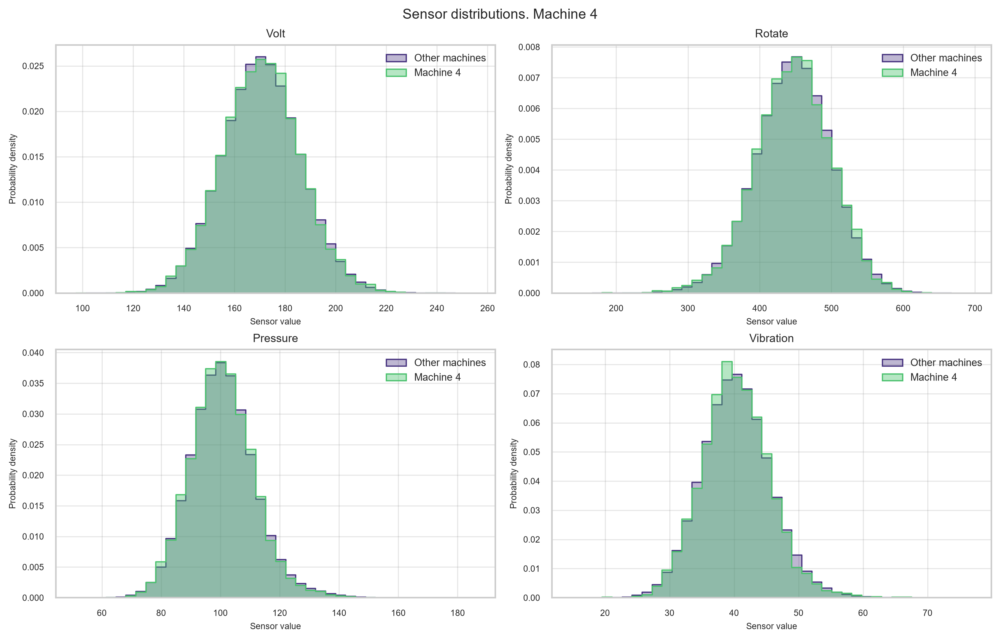

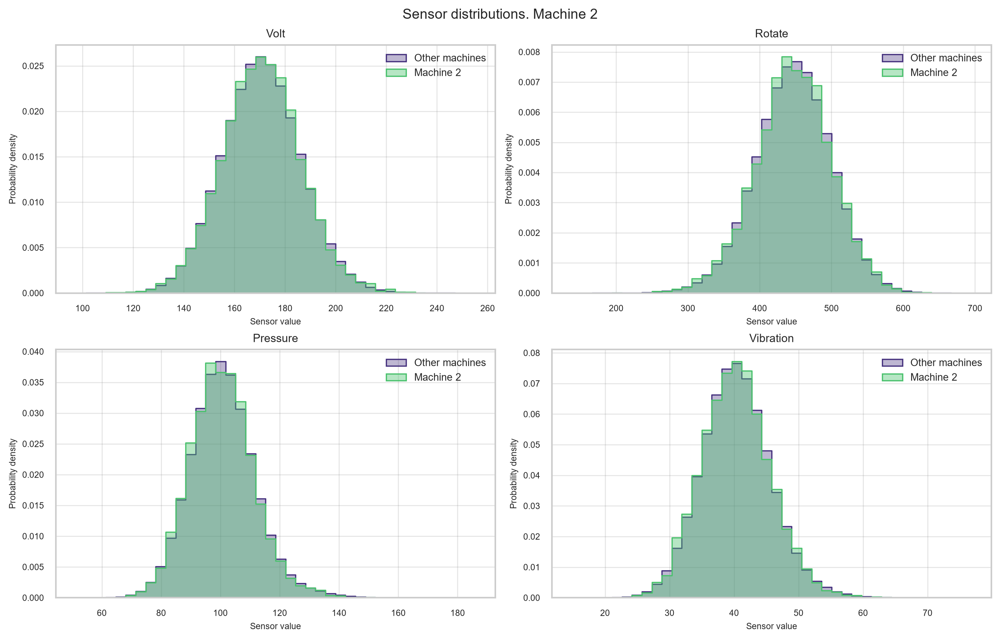

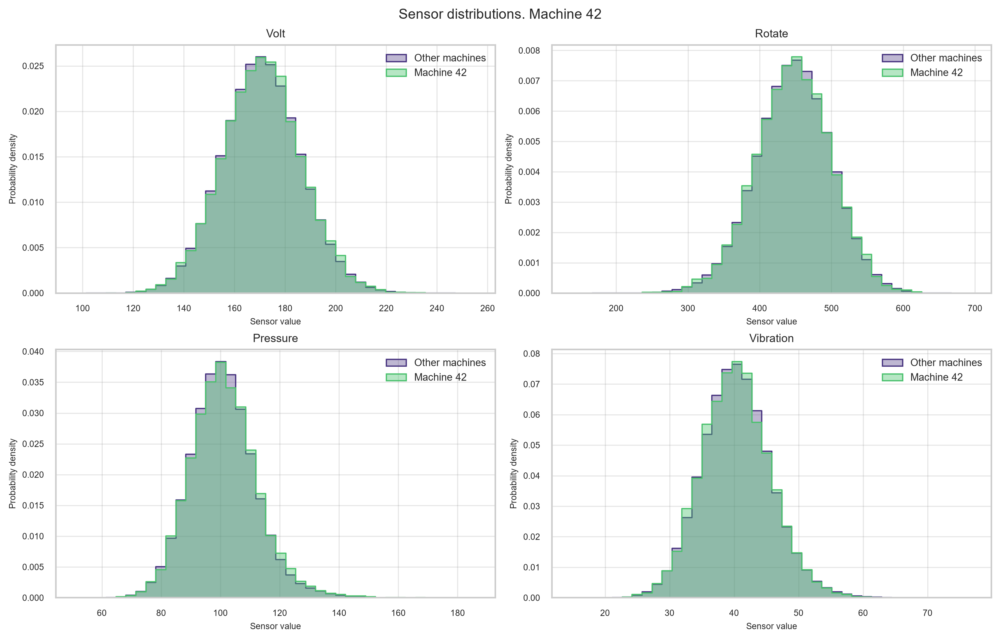

In [11]:
# compare all sensor distributions for selected machines
for machine_id in (4, 2, 42):
    plot_sensor_distribution(
        telemetry, machine_id, sensors
    )

The distributions of all four telemetry parameters for selected machines closely match those of the remaining fleet. Most distributions are approximately symmetric and unimodal, although pressure exhibits slight right-skewness. No substantial differences in central tendency, variability, or distribution shape are visually apparent. These results suggest that the selected machines exhibit typical sensor distributions relative to the fleet

#### Temporal Distributions

In [12]:
# define quantile-based temporal distribution function
def plot_sensor_temporal_distribution(telemetry, machine_id, sensor):

    mask = telemetry['machineID'].eq(machine_id)
    data = telemetry.loc[mask, ['datetime', sensor]].dropna().copy()
    
    if data.empty:
         raise ValueError(f'No valid {sensor} values for machine {machine_id}')

    data['month'] = data['datetime'].dt.month
    data['weekday'] = data['datetime'].dt.day_of_week
    data['hour'] = data['datetime'].dt.hour

    calendar = [
        ('month', 'Month', range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']),
        ('weekday', 'Weekday', range(7), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']),
        ('hour', 'Hour', range(24), list(range(24)))
    ]

    fig, axes = plt.subplots(1, 3, figsize=(12, 5), layout='constrained')
    for ax, (column, title, order, labels) in zip(axes, calendar):
        
        # get quantiles
        quantiles = [0.05, 0.25, 0.5, 0.75, 0.95]
        q = data.groupby(column)[sensor].quantile(quantiles).unstack().reindex(order)
        
        y = np.arange(len(q))
        ax.hlines(y, q[0.05], q[0.95], linewidth=1, color=sns.color_palette()[0], alpha=0.5, label='5–95%')
        ax.hlines(y, q[0.25], q[0.75], linewidth=4, color=sns.color_palette()[0], alpha=0.7, label='25–75%')
        ax.scatter(q[0.5], y, s=22, color='tomato', zorder=3, label='Median')
        
        ax.set(title=f'{sensor.capitalize()}. {title}', xlabel=sensor.capitalize())
        ax.set_yticks(y, labels=labels)
        ax.invert_yaxis()

    # axes[0].legend(loc='best')
    fig.suptitle(f'Quantile-based temporal distribution. Machine {machine_id}', fontsize=11)
    
    plt.show()

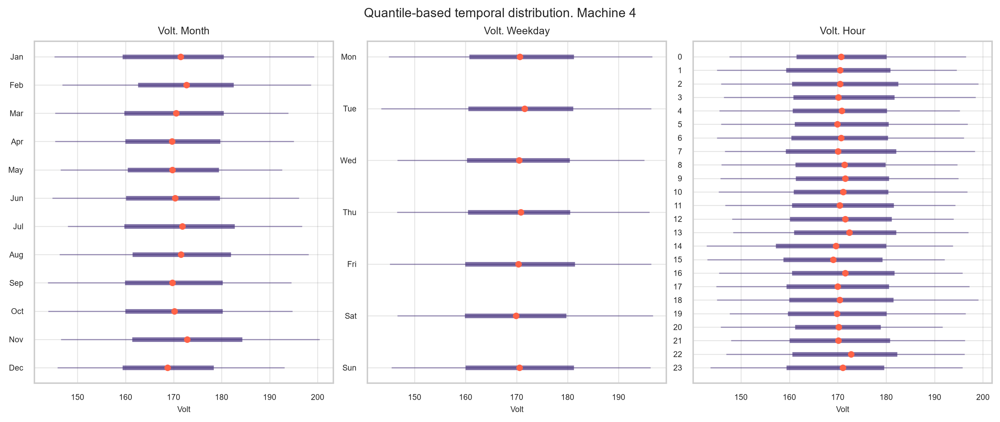

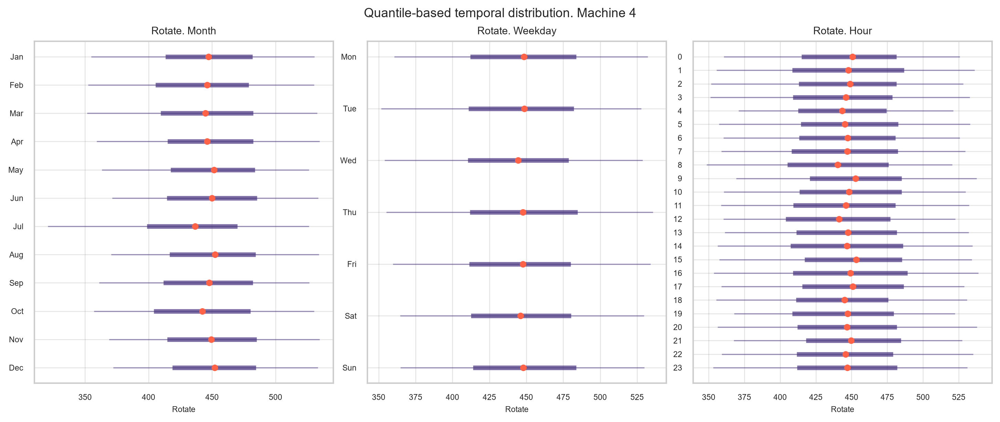

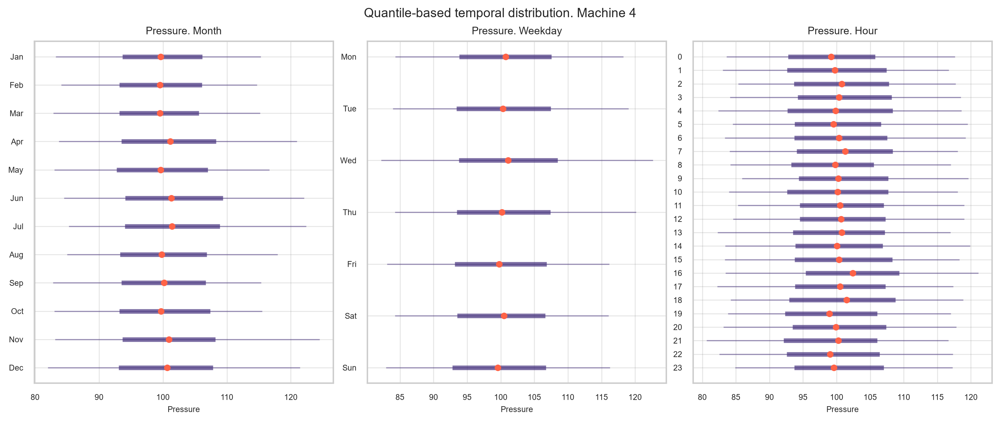

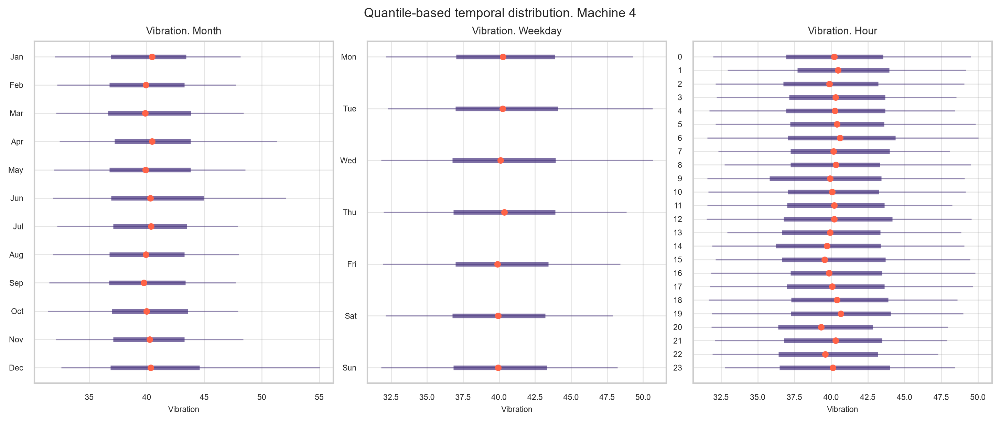

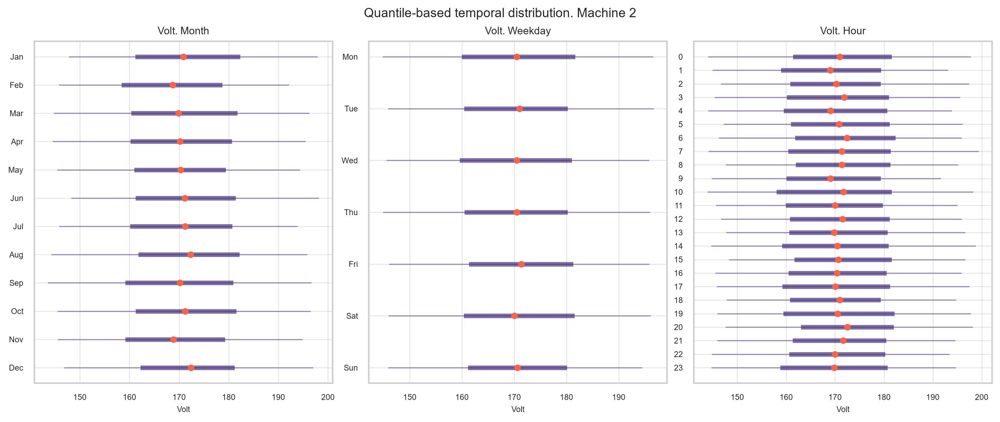

...

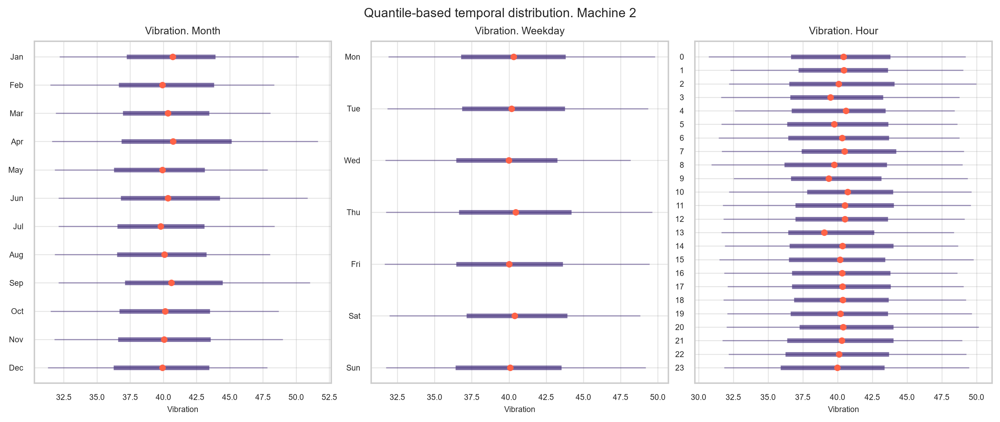

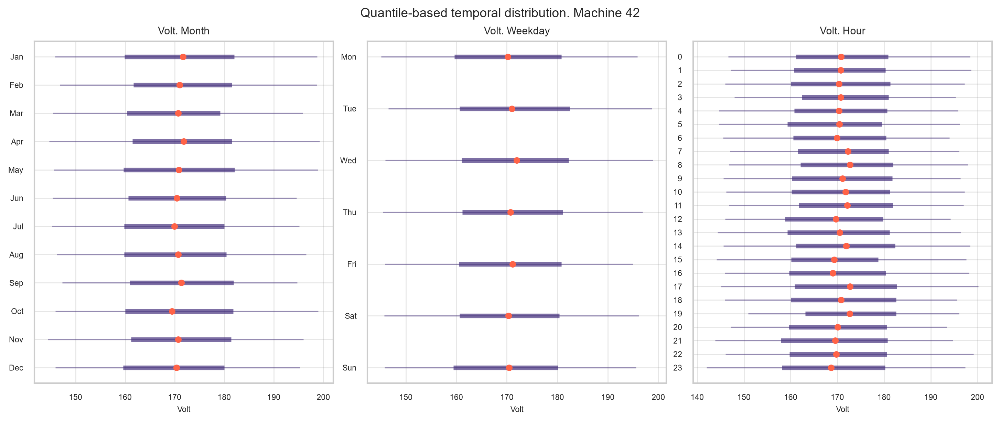

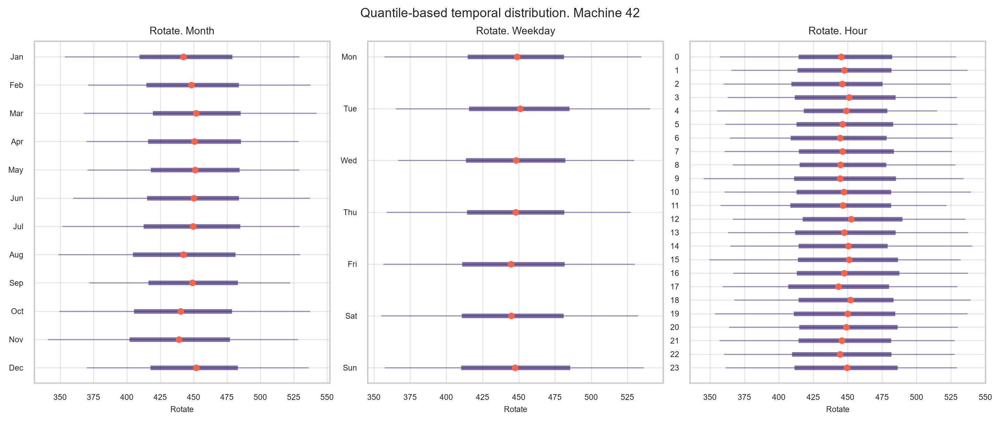

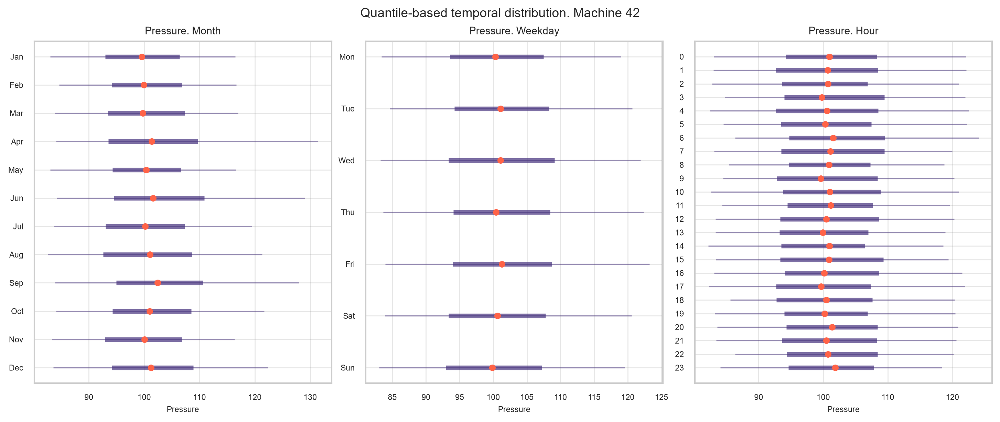

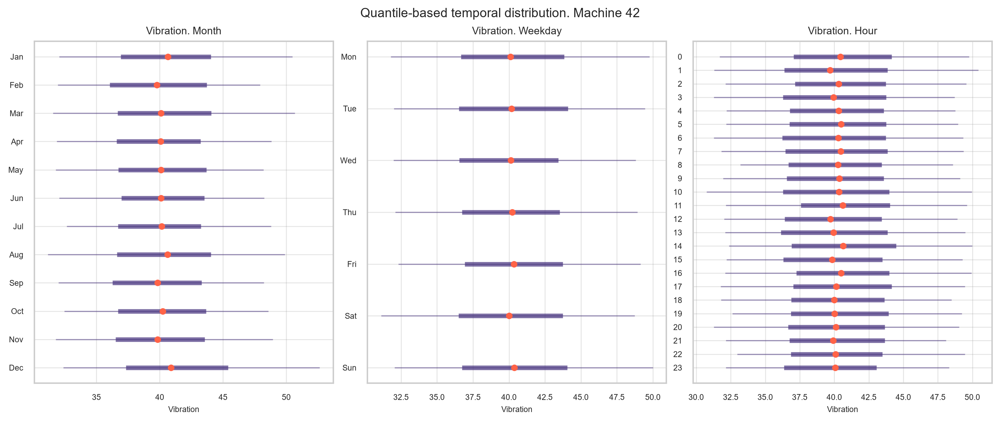

In [13]:
# compare all sensor temporal distributions for selected machines
for machine_id in (4, 2, 42):
    for sensor in sensors:
        plot_sensor_temporal_distribution(
            telemetry, machine_id, sensor
        )

The quantile-based temporal distributions of all four telemetry sensors for selected machines show no pronounced monthly, weekly, or hourly patterns. Median values and interquartile ranges remain relatively stable across all temporal groups, with only minor fluctuations. These results suggest limited calendar-related variation in the sensor measurements

#### Autocorrelation

In [14]:
# define sensor autocorrelation function
def plot_sensor_autocorrelation(telemetry, machine_id, sensors, max_lag=172):
    
    mask = telemetry['machineID'].eq(machine_id)
    data = telemetry.loc[mask].dropna().sort_values('datetime')

    if data.empty:
        raise ValueError(f'Selected machine {machine_id} data is empty')

    if data['datetime'].duplicated().any() or not data['datetime'].diff().dropna().eq(pd.Timedelta(hours=1)).all():
        raise ValueError('ACF requires an uninterrupted hourly grid')

    lags = np.arange(1, max_lag + 1)
    reference_lags = (24, 48, 168)
    
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
    for ax, sensor in zip(axes.flat, sensors):
        
        series = data[sensor]
        correlations = np.array([series.autocorr(lag=lag) for lag in lags])

        ax.vlines(lags, 0, correlations, color='tab:blue', linewidth=0.6)
        ax.scatter(lags, correlations, s=7, color='tab:blue', alpha=0.7, zorder=3)
        ax.axhline(0, color='gray', linewidth=0.8)

        # highlight daily, two-day and weekly lags
        for lag in reference_lags:
            if lag <= max_lag:
                ax.axvline(lag, color='tab:red', linestyle='--', linewidth=0.7, alpha=0.7)
                ax.annotate(
                    f'{lag}h', xy=(lag, 1), 
                    xycoords=ax.get_xaxis_transform(),
                    xytext=(3, -4), textcoords='offset points',
                    rotation=90, va='top', ha='left',
                    color='tab:red', fontsize=8
                )
        
        ax.set(title=sensor.capitalize(), xlabel='Lag (hours)', ylabel='Autocorrelation', xlim=(0, max_lag + 3))

    for ax in axes.flat[len(sensors):]:
        ax.set_visible(False)

    fig.suptitle(f'Sensor autocorrelation. Machine {machine_id}', fontsize=11)

    plt.show()

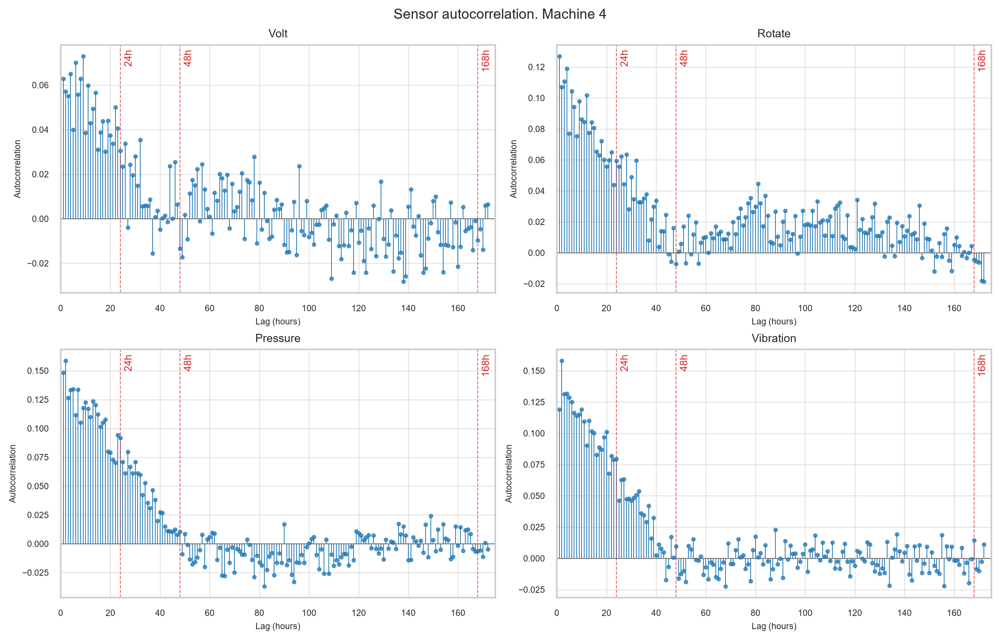

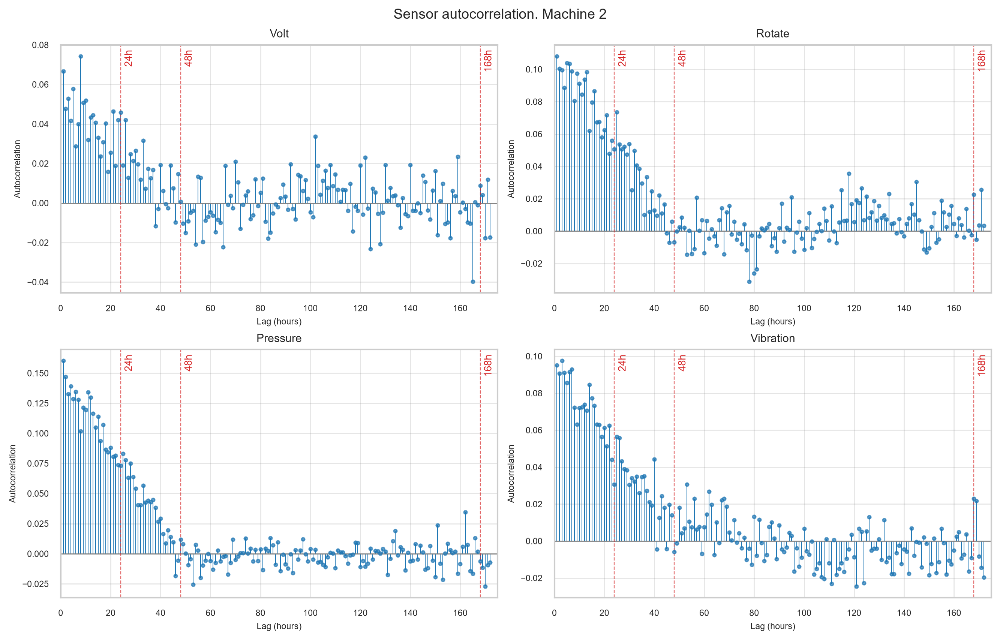

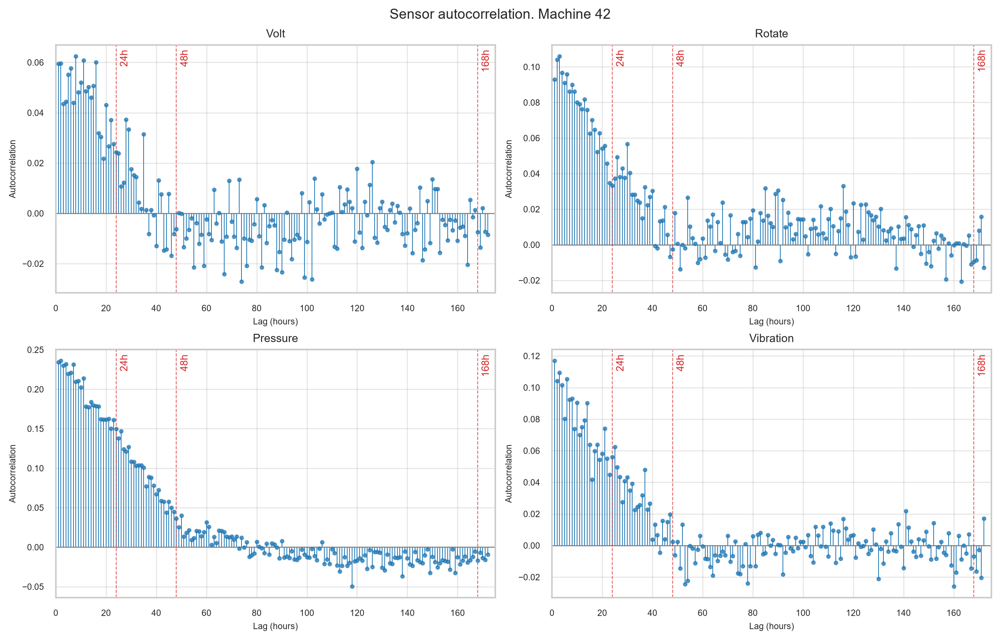

In [15]:
# inspect autocorrelation of telemetry sensors for selected machines
for machine_id in (4, 2, 42):
    plot_sensor_autocorrelation(
        telemetry, machine_id, sensors
    )

Autocorrelation analysis reveals positive short-term temporal dependence across all four telemetry parameters. No pronounced daily or weekly periodic patterns are apparent

#### Sensor Correlations

In [16]:
# define sensor correlations function
def plot_sensor_correlations(telemetry, machine_id, sensors):

    # correlations across all machines
    corr_fleet = telemetry[sensors].corr()

    # correlations for one selected machine
    mask = telemetry['machineID'].eq(machine_id)
    corr_machine = telemetry.loc[mask, sensors].corr()

    fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout='constrained')
    for ax, matrix, title in zip(axes, [corr_fleet, corr_machine], ['All machines', f'Machine {machine_id}']):
        sns.heatmap(
            matrix, ax=ax, annot=True, fmt='.2f', cmap='vlag',
            vmin=-1, vmax=1, center=0, square=True,
            cbar=ax is axes[-1], annot_kws={'size': 8}
        )
        ax.set_title(title)

    plt.show()

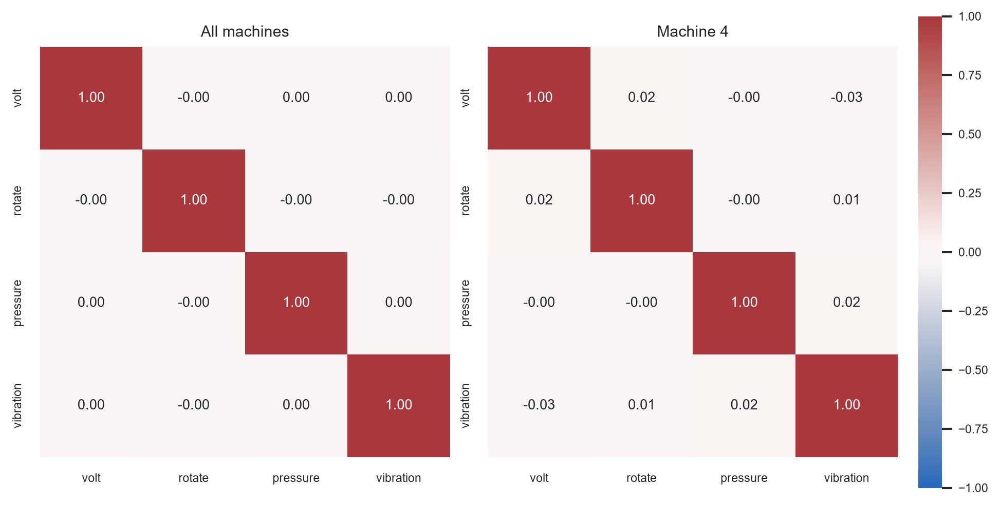

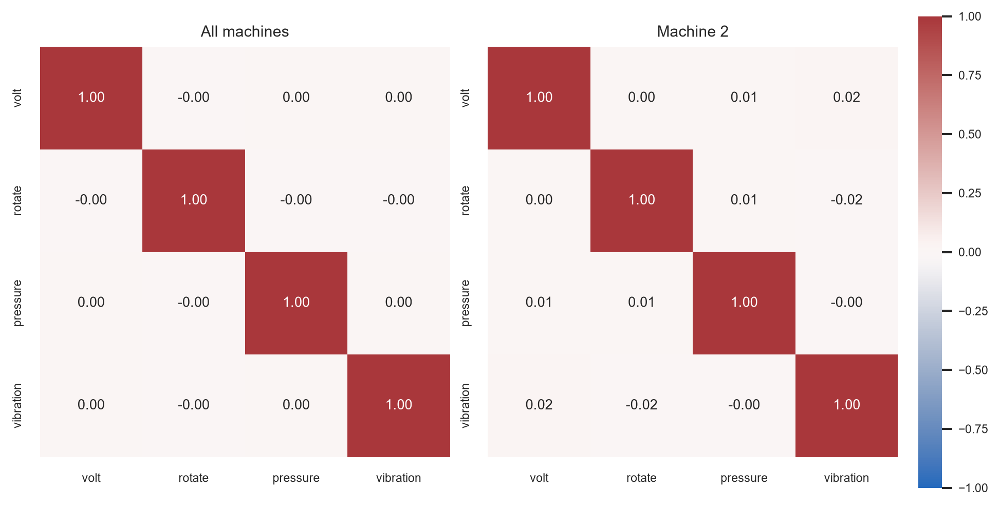

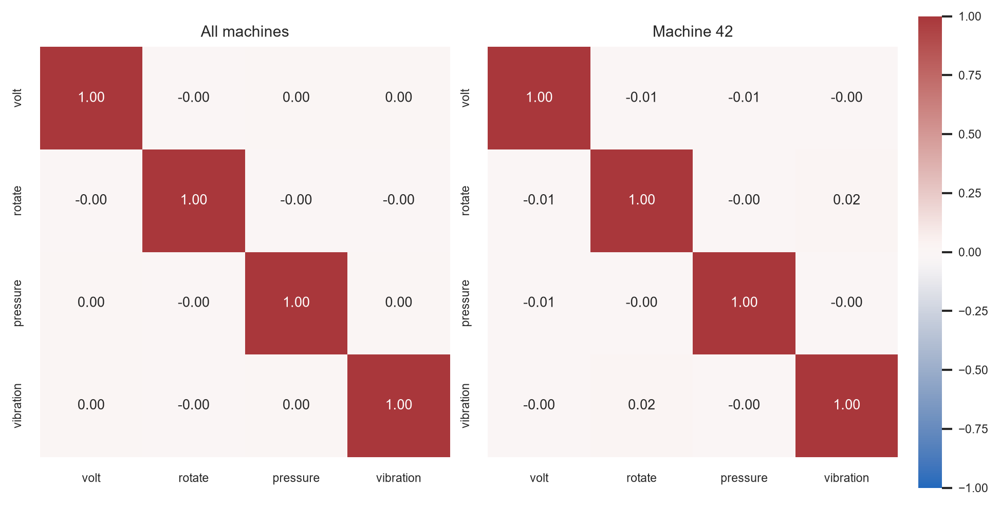

In [17]:
# compare linear correlations across all machines and one selected machine
for machine_id in (4, 2, 42):
    plot_sensor_correlations(
        telemetry, machine_id, sensors
    )

The correlation matrices reveal negligible linear relationships among the four telemetry parameters, both across the entire machine fleet and for machine individually. All off-diagonal Pearson correlation coefficients are close to zero, indicating no substantial pairwise linear dependence between sensor measurements. These findings suggest limited linear multicollinearity among the original telemetry variables

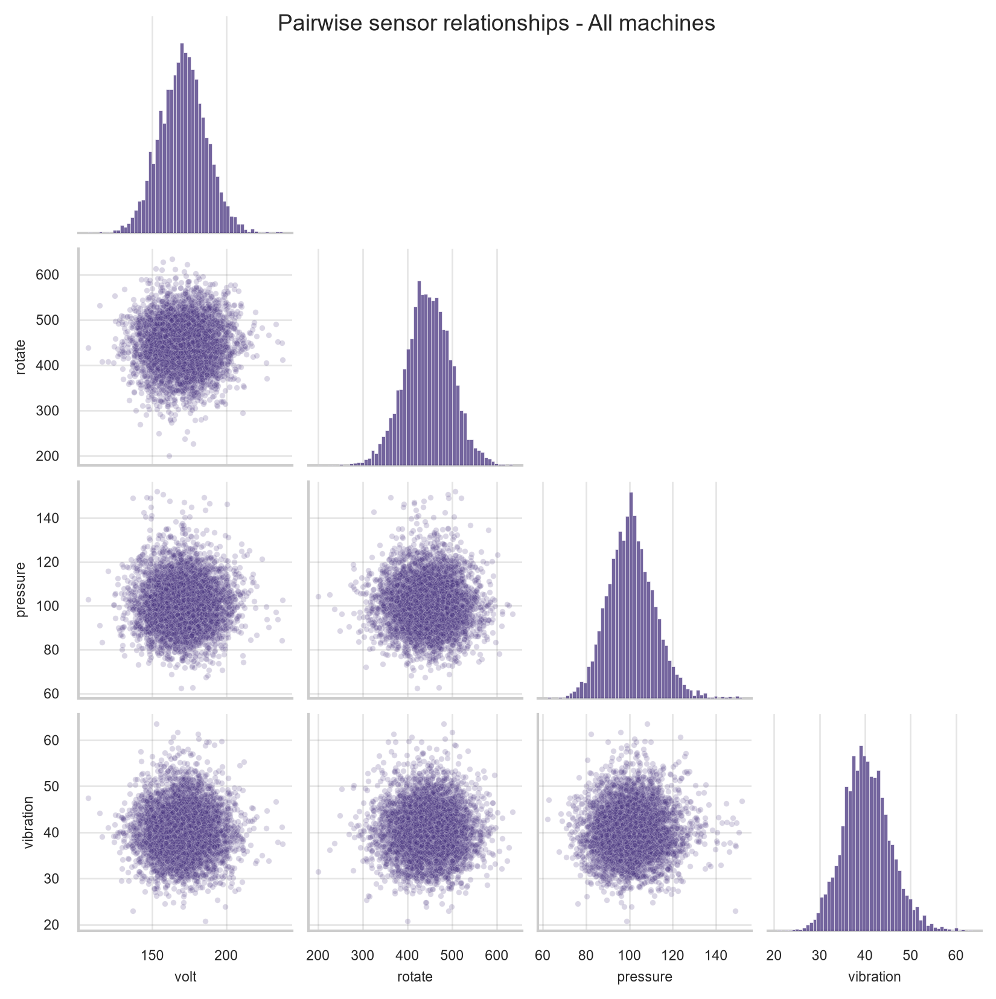

In [18]:
# examine pairwise relationships between telemetry parameters
sample = telemetry[sensors].dropna().sample(n=min(5000, len(telemetry)), random_state=42)

g = sns.pairplot(
    data=sample, vars=sensors,
    corner=True, diag_kind='hist',
    plot_kws={'s': 8, 'alpha': 0.2, 'rasterized': True},
    height=1.75
)
g.figure.suptitle('Pairwise sensor relationships - All machines', fontsize=11)

plt.show()

Pairwise scatter plots reveal no apparent linear or nonlinear relationships among the four telemetry parameters. The observations form approximately symmetric, diffuse point clouds without distinct clusters or systematic patterns. Individual sensor distributions are predominantly unimodal and approximately bell-shaped, with slight right-skewness in some parameters. These findings are consistent with the near-zero Pearson correlation coefficients observed earlier

#### Rolling Statistics

In [19]:
# define rolling statistics function
def plot_sensor_rolling_stats(telemetry, machine_id, sensor, windows=(24, 168)):

    mask = telemetry['machineID'].eq(machine_id)
    data = telemetry.loc[mask, ['datetime', sensor]]
    data = data.sort_values('datetime').set_index('datetime')[sensor].dropna()

    if data.empty:
        raise ValueError(f'Selected machine {machine_id} data is empty')

    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, layout='constrained')
    axes[0].plot(data.index, data, linewidth=0.5, alpha=0.3, label='Raw values')

    # define contrasting colors for rolling statistics
    colors = {24: '#0072B2', 168: '#D55E00'}
    
    for window in windows:
        # use time windows to preserve their meaning if gaps exist
        roll = data.rolling(f'{window}h', min_periods=max(2, window // 2))
        axes[0].plot(data.index, roll.mean(), color=colors[window], alpha=0.7, linewidth=1.0, label=f'{window}h mean')
        axes[1].plot(data.index, roll.std(), color=colors[window], alpha=0.7, linewidth=1.0, label=f'{window}h std')
    
    axes[0].set(title=f'{sensor.capitalize()}. Machine {machine_id}', ylabel='Sensor value')
    axes[1].set(xlabel='Datetime', ylabel='Rolling std')
    axes[0].legend(loc='upper right')
    axes[1].legend(loc='upper right')

    plt.show()

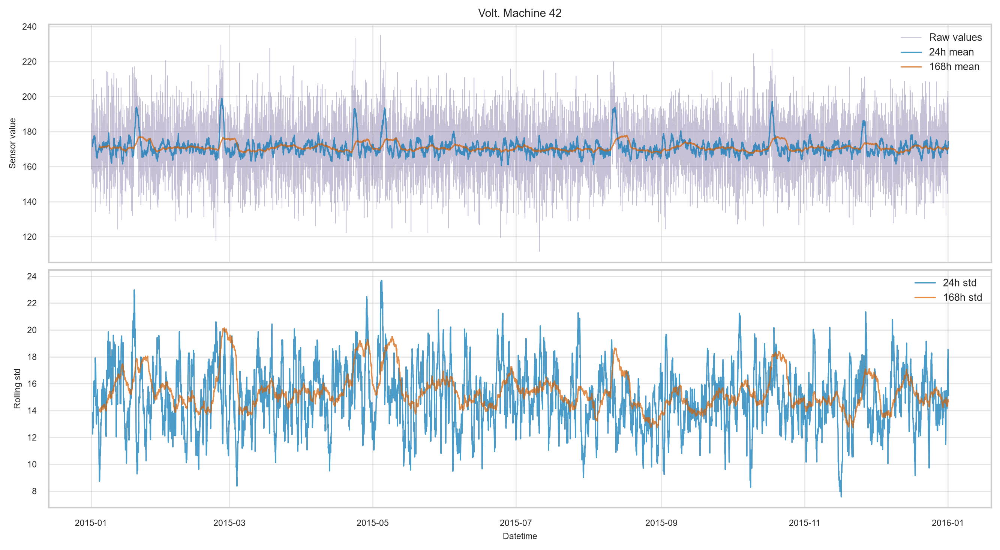

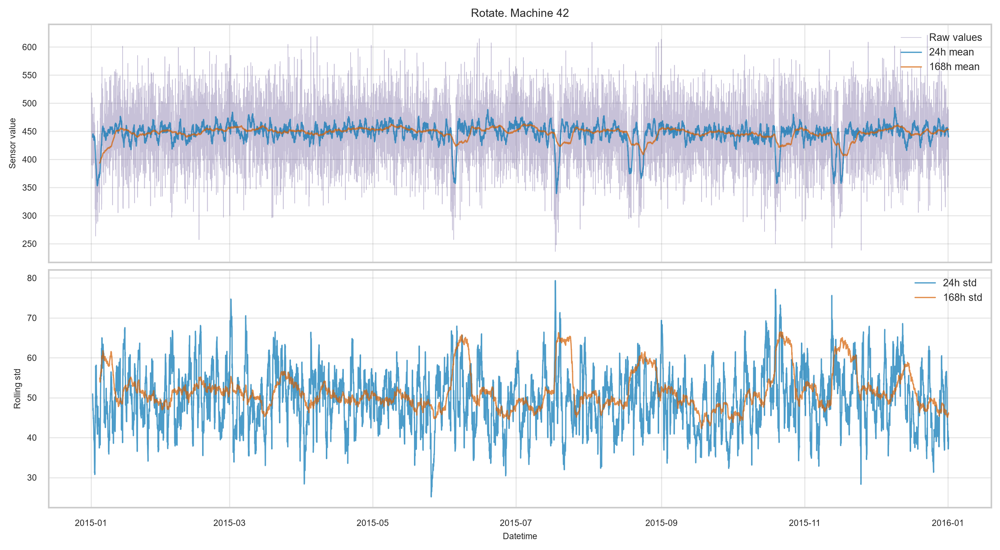

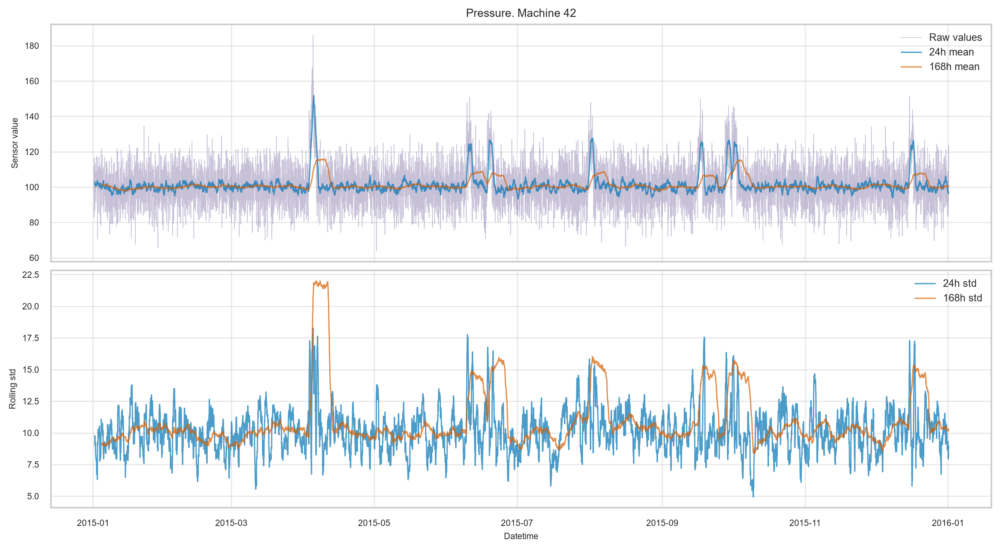

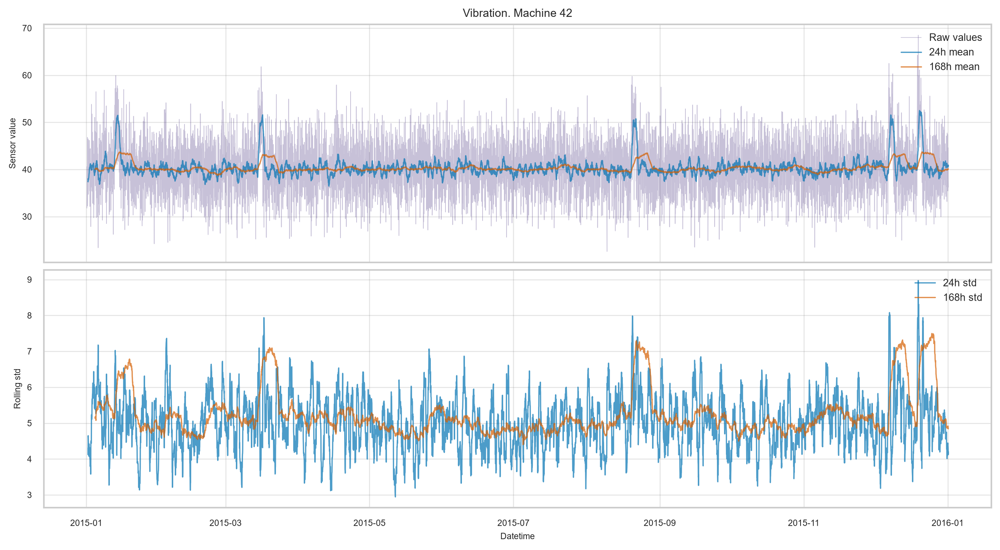

In [20]:
# inspect short- and long-term variability for each sensor
for sensor in sensors:
    plot_sensor_rolling_stats(
        telemetry=telemetry, machine_id=42, sensor=sensor
    )

Sensor measurements for Machine 42 exhibit a relatively stable baseline, interrupted by several pronounced short-term increases. These events are reflected in elevated 24-hour rolling means and increased short-term variability. The 168-hour rolling statistics respond more gradually and remain elevated after the spikes. No persistent long-term trend is apparent

### Event Analysis

Define reusable functions for analyzing error events, component replacements, and failures. The functions summarize event frequencies, temporal patterns, daily count distributions, and differences across machines

In [21]:
def summarize_events(events, event_col, total_machines):
    """Summarize event frequency and machine coverage by event type"""

    summary = events.groupby(event_col).agg(
        event_count=('machineID', 'size'),
        machine_count=('machineID', 'nunique')
    ).sort_index()

    # calculate the proportion of events and affected machines
    summary['event_share_pct'] = (
        summary['event_count']
        .div(len(events) if len(events) else np.nan)
        .mul(100)
    )
    summary['machine_share_pct'] = (
        summary['machine_count']
        .div(total_machines if total_machines else np.nan)
        .mul(100)
    )

    return summary

In [22]:
def plot_event_counts(summary, title, xlabel):
    """Plot event counts by event type"""

    fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
    bars = ax.bar(summary.index, summary['event_count'], alpha=0.8)

    ax.bar_label(bars, fmt='%.0f', padding=3, fontsize=10)
    ax.set(title=title, xlabel=xlabel, ylabel='Number of events')
    ax.margins(y=0.1)
    ax.set_axisbelow(True)

    plt.show()

In [23]:
def make_daily_event_counts(
    events, telemetry, event_col, event_types, window=7
):
    """Calculate daily event counts and rolling averages"""

    # build the complete daily timeline
    days = pd.date_range(
        telemetry['datetime'].min().normalize(),
        telemetry['datetime'].max().normalize(),
        freq='D',
        name='datetime'
    )

    # count events by day and type, including zero-event days
    daily_counts = (
        events
        .assign(day=events['datetime'].dt.normalize())
        .groupby(['day', event_col])
        .size()
        .unstack(event_col, fill_value=0)
        .reindex(index=days, columns=event_types, fill_value=0)
        .astype(int)
    )

    daily_counts.index.name = 'datetime'

    # identify days with complete hourly telemetry coverage
    hourly_coverage = (
        telemetry
        .assign(hour=telemetry['datetime'].dt.floor('h'))
        .drop_duplicates(['machineID', 'hour'])
        .assign(day=lambda df: df['hour'].dt.normalize())
        .groupby('day')
        .size()
        .reindex(days, fill_value=0)
    )

    expected_hours = 24 * telemetry['machineID'].nunique()
    complete_days = hourly_coverage.eq(expected_hours)

    # preserve incomplete days as missing observations
    daily_observed = daily_counts.where(complete_days, axis=0)

    # calculate total event counts and rolling averages
    daily_total = daily_observed.sum(axis=1, min_count=1)
    rolling_total = daily_total.rolling(window, min_periods=window).mean()
    rolling_by_type = daily_observed.rolling(window, min_periods=window).mean()

    return (
        daily_counts,
        complete_days,
        daily_total,
        rolling_total,
        rolling_by_type
    )

In [24]:
def plot_daily_event_trends(
    daily_total, rolling_total, rolling_by_type,
    title, type_title, ylabel, type_label
):
    """Plot daily event counts and rolling averages by event type"""

    fig, axs = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout='constrained')

    # plot daily total event counts and rolling average of total events
    axs[0].plot(daily_total.index, daily_total, color='gray', alpha=0.4, linewidth=0.8, label='Daily count')
    axs[0].plot(rolling_total.index, rolling_total,label='7-day moving average')

    axs[0].set(title=title, ylabel=ylabel)
    axs[0].legend()

    # plot rolling averages for individual event types
    colors = sns.color_palette('deep', len(rolling_by_type.columns))

    for event_type, color in zip(rolling_by_type.columns, colors):
        axs[1].plot(rolling_by_type.index, rolling_by_type[event_type], color=color, label=event_type)

    axs[1].set(title=type_title, xlabel='Date', ylabel=ylabel)
    axs[1].legend(title=type_label)

    plt.show()

In [25]:
def summarize_daily_events(daily_counts, complete_days):
    """Summarize daily event counts for complete observation days"""

    # select days with complete telemetry coverage
    daily_complete = daily_counts.loc[complete_days]

    # calculate descriptive statistics by event type
    summary = pd.DataFrame({
        'mean': daily_complete.mean(),
        'median': daily_complete.median(),
        'std': daily_complete.std(),
        'p95': daily_complete.quantile(0.95),
        'max': daily_complete.max(),
        'zero_days': daily_complete.eq(0).sum(),
        'zero_days_pct': daily_complete.eq(0).mean().mul(100),
    })
    summary.index.name = daily_counts.columns.name

    return summary

In [26]:
def plot_daily_event_distributions(
    daily_counts, complete_days, xlabel,
    title_prefix, ncols=2
):
    """Plot daily event count distributions by event type"""

    # select days with complete telemetry coverage
    data = daily_counts.loc[complete_days]
    event_types = data.columns

    # define histogram bins for integer event counts
    max_count = int(data.to_numpy().max())
    bins = np.arange(-0.5, max_count + 1.5, 1)

    # configure subplot layout
    nrows = int(np.ceil(len(event_types) / ncols))
    fig, axs = plt.subplots(nrows, ncols,
        figsize=(3 * ncols, 3 * nrows),
        sharey=True,
        layout='constrained',
        squeeze=False
    )

    # plot event count distributions
    colors = sns.color_palette('deep', len(event_types))
    for ax, event_type, color in zip(axs.flat, event_types, colors):
        
        values = data[event_type]
        # plot event distribution
        sns.histplot(
            x=values, bins=bins, 
            stat='probability', 
            color=color, edgecolor='white', 
            ax=ax
        )
        # highlight mean daily event count
        ax.axvline(
            values.mean(), 
            color='black', 
            linestyle='--', linewidth=0.8, 
            label=f'Mean: {values.mean():.2f}'
        )
        ax.set(
            title=f'{title_prefix}: {event_type}',
            xlabel=xlabel,
            ylabel='Proportion of days',
            xlim=(-0.5, max_count + 0.5)
        )

        ax.xaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(integer=True))
        ax.legend()

    # hide unused subplots
    for ax in list(axs.flat)[len(event_types):]:
        ax.set_visible(False)

    plt.show()

In [27]:
def summarize_events_by_machine(
    events, machines, event_col, event_types, total_name
):
    """Count events by machine and type, sorted by total event count"""

    # count events of each type for every machine
    counts = (
        pd.crosstab(events['machineID'], events[event_col])
        .reindex(
            index=machines['machineID'].drop_duplicates().sort_values(),
            columns=event_types,
            fill_value=0
        )
    )
    # calculate total event counts and sort machines
    totals = (
        counts.sum(axis=1)
        .rename(total_name)
        .sort_values(ascending=False, kind='stable')
    )
    counts = counts.loc[totals.index]

    return counts, totals

In [28]:
def plot_machine_event_counts(totals, title, ylabel):
    """Plot total event counts by machine"""

    fig, ax = plt.subplots(figsize=(12, 4), layout='constrained')

    positions = np.arange(len(totals))
    ax.bar(positions, totals.to_numpy())

    ax.set_xticks(positions, labels=totals.index.astype(str), rotation=90, fontsize=7)
    ax.set(title=title, xlabel='Machine ID, ordered by total event count', ylabel=ylabel)

    plt.show()

In [29]:
def plot_machine_event_heatmap(counts, title, ylabel):
    """Plot event counts by type and machine as a heatmap"""

    fig, ax = plt.subplots(figsize=(12, 4), layout='constrained')

    sns.heatmap(
        counts.T,
        cmap='flare',
        vmin=0,
        xticklabels=True,
        yticklabels=True,
        cbar_kws={'label': 'Number of events'},
        ax=ax
    )

    ax.set(title=title, xlabel='Machine ID, ordered by total event count', ylabel=ylabel)
    ax.tick_params(axis='x', labelrotation=90, labelsize=7)
    ax.tick_params(axis='y', labelrotation=0)

    plt.show()

#### Error Events

In [30]:
# sort error events and define error types
errors = errors.sort_values(['machineID', 'datetime'])
ERROR_TYPES = sorted(errors['errorID'].unique())

display(errors)

,datetime,machineID,errorID
0,2015-01-03 07:00:00,1,error1
1,2015-01-03 20:00:00,1,error3
2,2015-01-04 06:00:00,1,error5
3,2015-01-10 15:00:00,1,error4
4,2015-01-22 10:00:00,1,error4
...,...,...,...
3914,2015-11-21 08:00:00,100,error2
3915,2015-12-04 02:00:00,100,error1
3916,2015-12-08 06:00:00,100,error2
3917,2015-12-08 06:00:00,100,error3


In [31]:
# summarize error frequency and machine coverage
error_summary = summarize_events(
    events=errors, 
    event_col='errorID', 
    total_machines=machines['machineID'].nunique()
)

display(error_summary.round(2))

,event_count,machine_count,event_share_pct,machine_share_pct
errorID,,,,
error1,1010,100,25.77,100.0
error2,988,100,25.21,100.0
error3,838,100,21.38,100.0
error4,727,100,18.55,100.0
error5,356,93,9.08,93.0


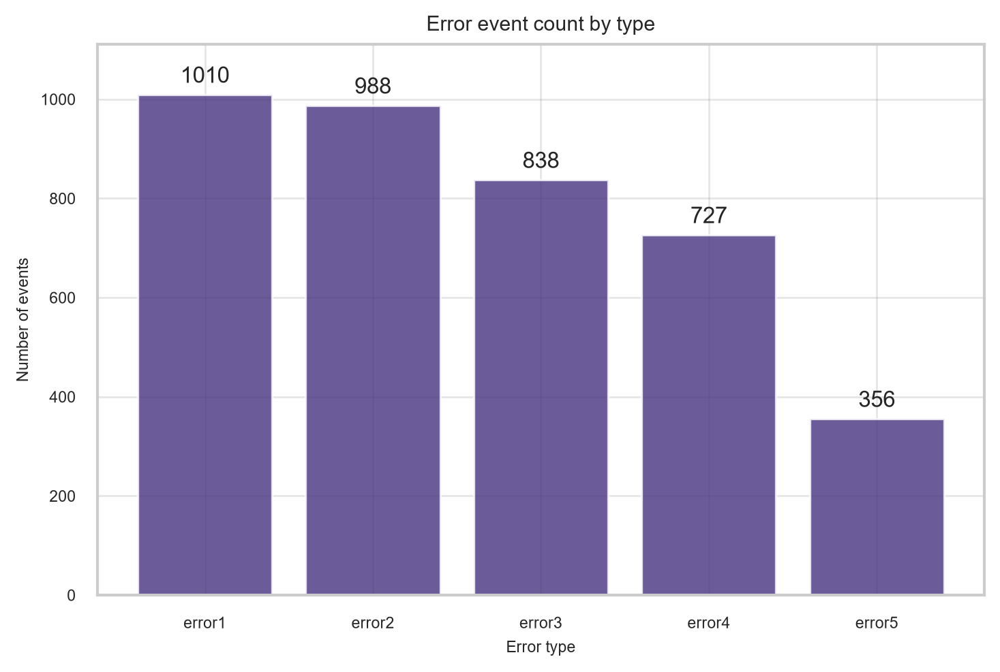

In [32]:
# compare event counts across error types
plot_event_counts(
    summary=error_summary,
    title='Error event count by type',
    xlabel='Error type'
)

Error frequencies vary across types, with error1 (25.77%) and error2 (25.21%) being the most common, while error5 (9.08%) occurs substantially less frequently

Aggregate error events into daily counts across all machines, including days without errors from telemetry. Exclude days with incomplete telemetry coverage and use rolling seven-day averages to highlight changes in error frequency

In [33]:
# calculate daily error counts and rolling averages
(
    daily_errors,
    complete_days,
    daily_errors_total,
    weekly_errors_total,
    weekly_errors_by_type
) = make_daily_event_counts(
    events=errors, 
    telemetry=telemetry, 
    event_col='errorID', 
    event_types=ERROR_TYPES
)

print(f'Complete days: {complete_days.sum()} / {len(complete_days)}')

Complete days: 364 / 366


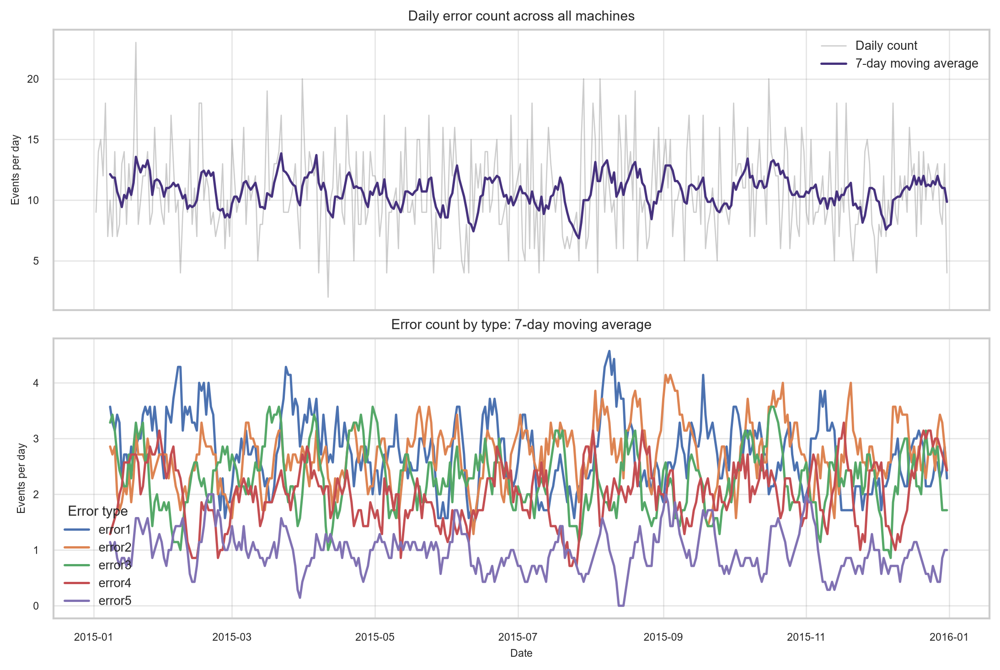

In [34]:
# examine daily error counts and rolling averages
plot_daily_event_trends(
    daily_total=daily_errors_total,
    rolling_total=weekly_errors_total,
    rolling_by_type=weekly_errors_by_type,
    title='Daily error count across all machines',
    type_title='Error count by type: 7-day moving average',
    ylabel='Events per day',
    type_label='Error type'
)

Across the fleet, the daily error count fluctuates around a relatively stable level, with the seven-day moving average mostly ranging from approximately 9 to 13 events per day. Short-lived spikes occur, but no sustained upward or downward trend is apparent. Error1 and error2 are generally more frequent, whereas error5 remains the least frequent type. These plots describe aggregate temporal variation; they do not establish a relationship between errors and subsequent failures

In [35]:
# summarize daily error count distributions
daily_errors_summary = summarize_daily_events(
    daily_counts=daily_errors, 
    complete_days=complete_days
)

display(daily_errors_summary.round(2))

,mean,median,std,p95,max,zero_days,zero_days_pct
errorID,,,,,,,
error1,2.76,2.5,1.77,6.0,10,22,6.04
error2,2.71,3.0,1.63,5.0,8,23,6.32
error3,2.29,2.0,1.57,5.0,7,41,11.26
error4,1.99,2.0,1.46,5.0,8,56,15.38
error5,0.98,1.0,0.97,3.0,4,136,37.36


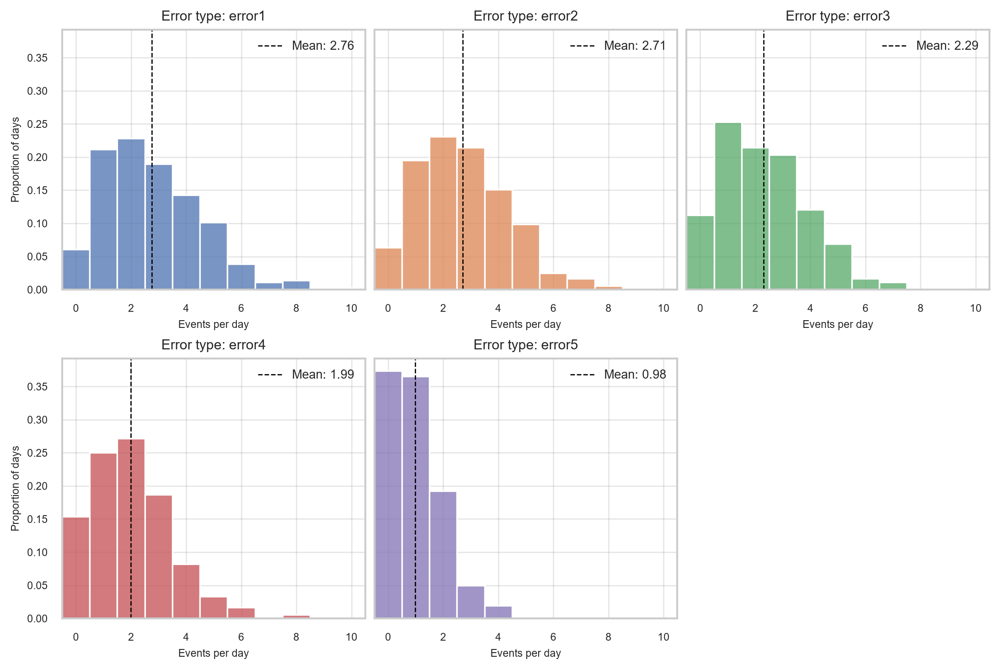

In [36]:
# compare daily error count distributions
plot_daily_event_distributions(
    daily_counts=daily_errors,
    complete_days=complete_days,
    xlabel='Events per day',
    title_prefix='Error type',
    ncols=3
)

Daily error counts across the fleet show right-skewed distributions, with low counts occurring more frequently than high counts. Error1 and error2 have similar mean frequencies of approximately 2.7 events per day, although error1 exhibits slightly greater variability. Error5 is the least frequent type, averaging approximately one event per day and occurring on no machines on 37.4% of complete observation days

In [37]:
# summarize error counts by machine
errors_per_machine, errors_machine_totals = summarize_events_by_machine(
    events=errors, 
    machines=machines, 
    event_col='errorID', 
    event_types=ERROR_TYPES, 
    total_name='total_errors'
)

# show top-10 machines
display(
    errors_per_machine
    .assign(total_errors=errors_machine_totals)
    .head(10)
)

errorID,error1,error2,error3,error4,error5,total_errors
machineID,,,,,,
22,12,8,14,18,8,60
78,11,15,14,5,9,54
99,9,17,15,8,5,54
15,14,14,9,10,4,51
49,7,13,10,9,12,51
81,19,14,8,8,2,51
63,13,10,11,8,8,50
79,11,13,15,5,6,50
88,9,17,12,8,4,50


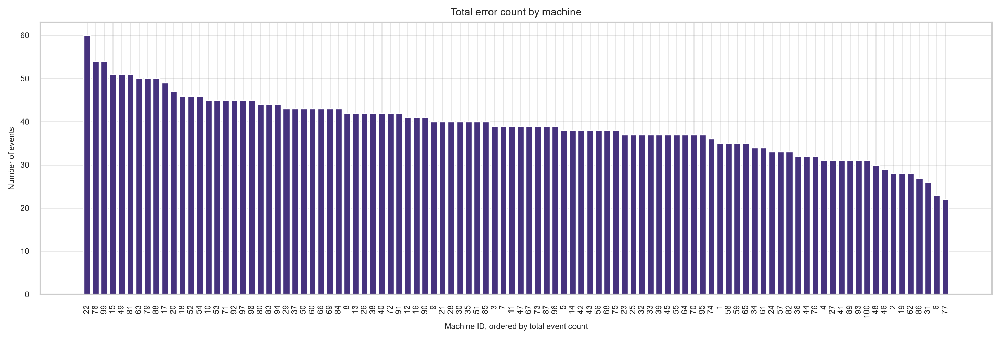

In [38]:
# compare total error counts across machines
plot_machine_event_counts(
    totals=errors_machine_totals,
    title='Total error count by machine',
    ylabel='Number of events'
)

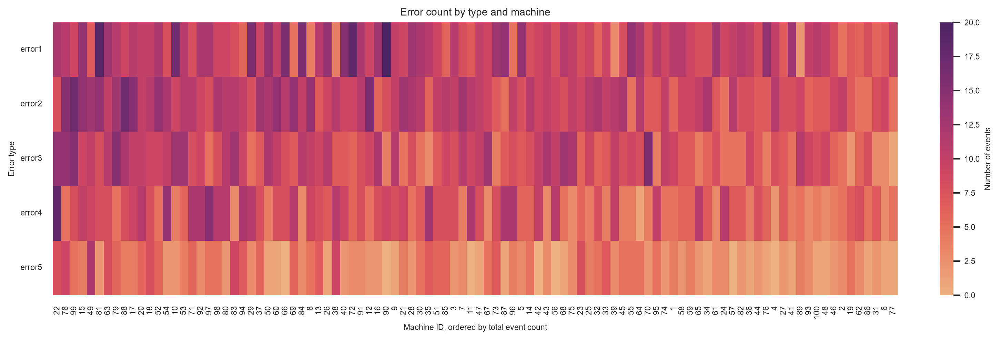

In [39]:
# compare error-type counts across machines
plot_machine_event_heatmap(
    counts=errors_per_machine,
    title='Error count by type and machine',
    ylabel='Error type'
)

#### Component Replacements

In [40]:
# sort maintenance events and define replacement component types
maint = maint.sort_values(['machineID', 'datetime'])
COMPONENTS = sorted(maint['comp'].unique())

display(maint)

,datetime,machineID,comp
0,2014-06-01 06:00:00,1,comp2
1,2014-07-16 06:00:00,1,comp4
2,2014-07-31 06:00:00,1,comp3
3,2014-12-13 06:00:00,1,comp1
4,2015-01-05 06:00:00,1,comp4
...,...,...,...
3281,2015-10-10 06:00:00,100,comp3
3282,2015-10-25 06:00:00,100,comp4
3283,2015-11-09 06:00:00,100,comp4
3284,2015-12-09 06:00:00,100,comp2


In [41]:
# select replacements recorded during the telemetry period
maint_observed = maint.loc[
    maint['datetime'].between(
        telemetry['datetime'].min(),
        telemetry['datetime'].max(),
        inclusive='both'
    )
].copy()

display(maint_observed)

,datetime,machineID,comp
4,2015-01-05 06:00:00,1,comp4
5,2015-01-05 06:00:00,1,comp1
6,2015-01-20 06:00:00,1,comp3
7,2015-01-20 06:00:00,1,comp1
8,2015-02-04 06:00:00,1,comp4
...,...,...,...
3281,2015-10-10 06:00:00,100,comp3
3282,2015-10-25 06:00:00,100,comp4
3283,2015-11-09 06:00:00,100,comp4
3284,2015-12-09 06:00:00,100,comp2


In [42]:
# summarize replacement frequency and machine coverage
maint_summary = summarize_events(
    events=maint_observed, 
    event_col='comp', 
    total_machines=machines['machineID'].nunique()
)

display(maint_summary.round(2))

,event_count,machine_count,event_share_pct,machine_share_pct
comp,,,,
comp1,704,100,24.39,100.0
comp2,763,100,26.44,100.0
comp3,708,100,24.53,100.0
comp4,711,100,24.64,100.0


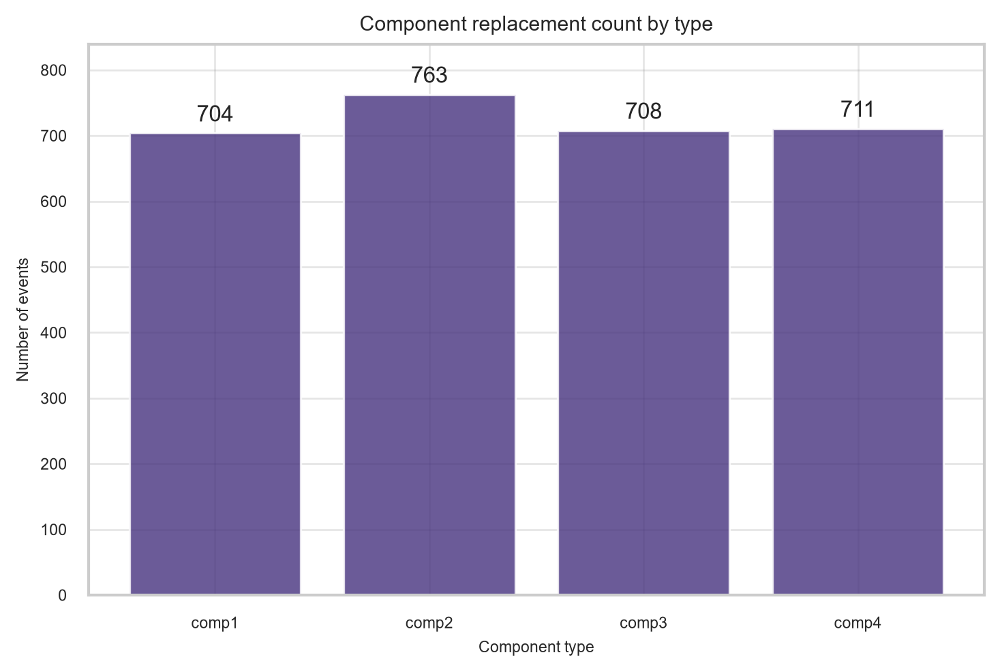

In [43]:
# compare replacement counts across component types
plot_event_counts(
    summary=maint_summary,
    title='Component replacement count by type',
    xlabel='Component type'
)

Replacement counts are relatively evenly distributed across the four component types. Comp2 has the highest count at 763 replacements (26.44%), while the other components have similar counts ranging from 704 to 711. This difference alone does not indicate lower reliability, as the records include both scheduled and failure-related replacements

Aggregate replacement events into daily counts across all machines, including days without replacements from telemetry. Exclude days with incomplete telemetry coverage and use trailing seven-day averages to highlight changes in replacement frequency

In [44]:
# calculate daily replacement counts and rolling averages
(
    daily_maint,
    complete_days,
    daily_maint_total,
    weekly_maint_total,
    weekly_maint_by_type
) = make_daily_event_counts(
    events=maint_observed, 
    telemetry=telemetry, 
    event_col='comp', 
    event_types=COMPONENTS
)

print(f'Complete days: {complete_days.sum()} / {len(complete_days)}')

Complete days: 364 / 366


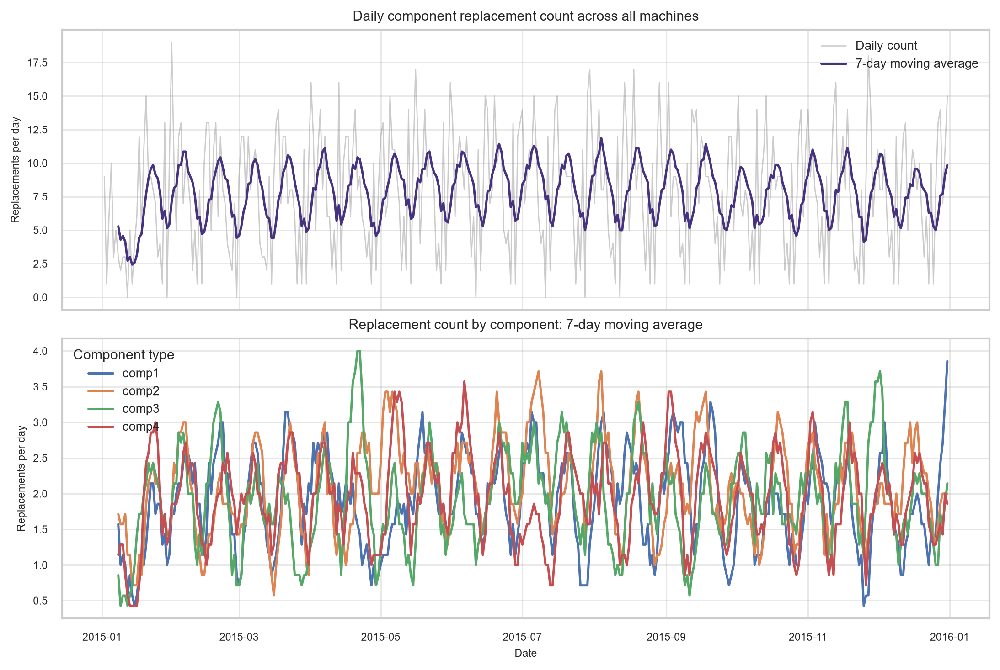

In [45]:
# examine daily replacement counts and rolling averages
plot_daily_event_trends(
    daily_total=daily_maint_total,
    rolling_total=weekly_maint_total,
    rolling_by_type=weekly_maint_by_type,
    title='Daily component replacement count across all machines',
    type_title='Replacement count by component: 7-day moving average',
    ylabel='Replacements per day',
    type_label='Component type'
)

Daily replacement counts across the fleet exhibit a pronounced recurring pattern. The seven-day moving average suggests a cycle of approximately two weeks, with no clear sustained upward or downward trend after the initial period. Recurring fluctuations are visible across all four component types. This pattern is consistent with scheduled maintenance

In [46]:
# summarize daily replacement count distributions
daily_maint_summary = summarize_daily_events(
    daily_counts=daily_maint, 
    complete_days=complete_days
)

display(daily_maint_summary.round(2))

,mean,median,std,p95,max,zero_days,zero_days_pct
comp,,,,,,,
comp1,1.92,2.0,1.60,5.0,8,79,21.70
comp2,2.09,2.0,1.58,5.0,7,64,17.58
comp3,1.94,2.0,1.60,5.0,8,71,19.51
comp4,1.95,2.0,1.49,5.0,6,68,18.68


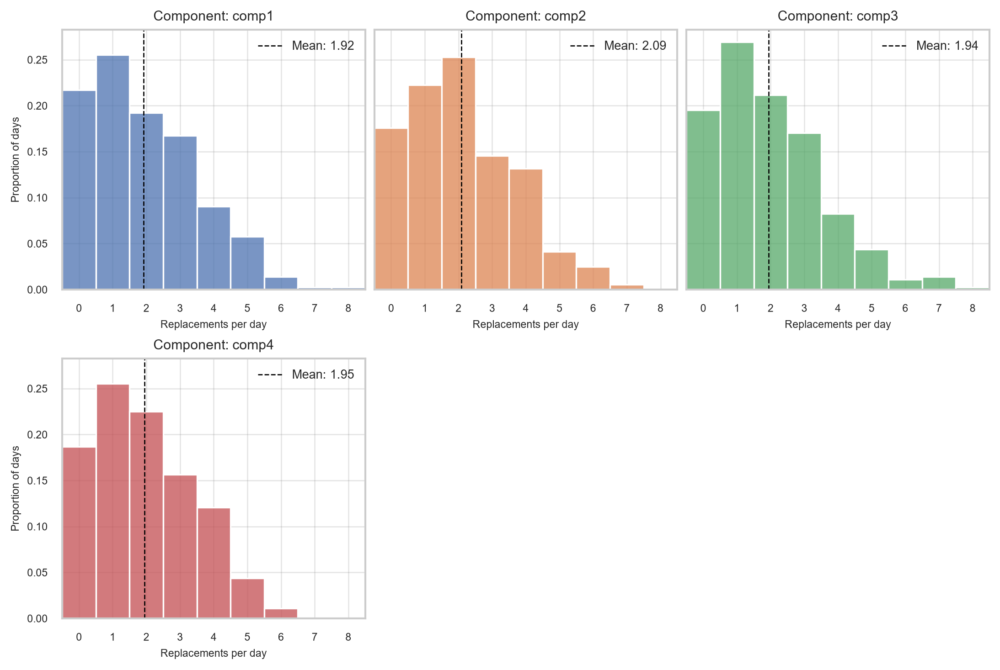

In [47]:
# compare daily replacement count distributions
plot_daily_event_distributions(
    daily_counts=daily_maint,
    complete_days=complete_days,
    xlabel='Replacements per day',
    title_prefix='Component',
    ncols=3
)

Daily component replacements across the fleet show right-skewed distributions, with low counts occurring more frequently than high counts. All components have similar mean frequencies of approximately 2.0 replacements per day

In [48]:
# summarize component replacement counts by machine
maint_per_machine, maint_machine_totals = summarize_events_by_machine(
    events=maint_observed, 
    machines=machines, 
    event_col='comp', 
    event_types=COMPONENTS, 
    total_name='total_replacements'
)

# show top-10 machines
display(
    maint_per_machine
    .assign(total_replacements=maint_machine_totals)
    .head(10)
)

comp,comp1,comp2,comp3,comp4,total_replacements
machineID,,,,,
66,10,5,9,11,35
68,7,8,7,13,35
70,6,7,13,9,35
10,6,14,7,7,34
14,8,10,10,6,34
24,10,10,8,6,34
27,6,8,11,9,34
42,7,10,6,11,34
84,6,10,8,10,34


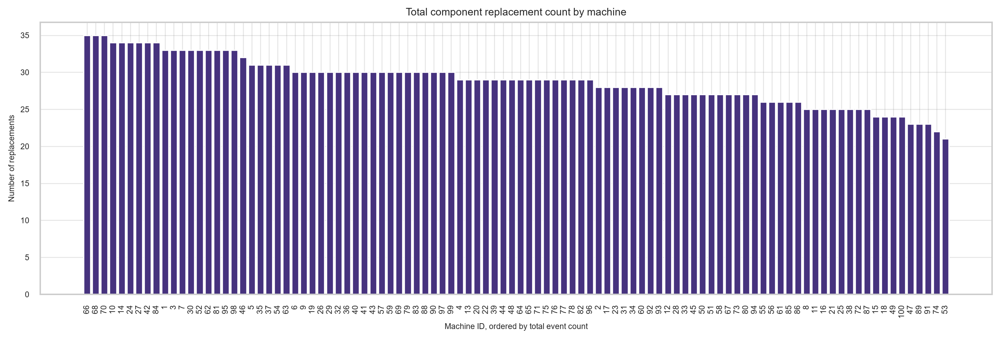

In [49]:
# compare total replacement counts across machines
plot_machine_event_counts(
    totals=maint_machine_totals,
    title='Total component replacement count by machine',
    ylabel='Number of replacements'
)

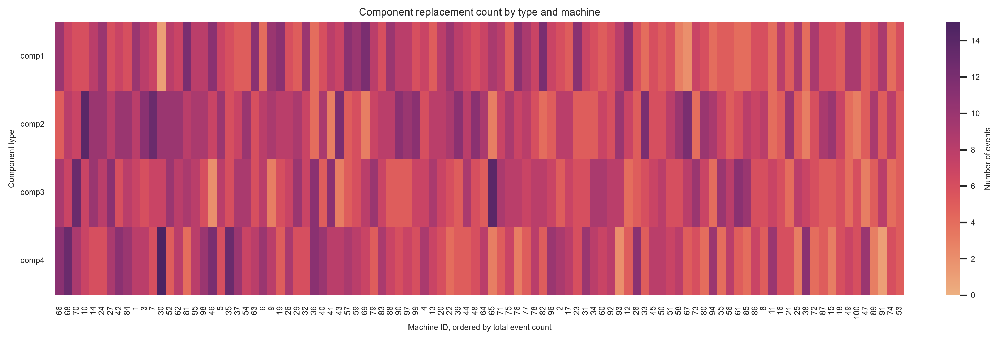

In [50]:
# compare component replacement counts across machines
plot_machine_event_heatmap(
    counts=maint_per_machine,
    title='Component replacement count by type and machine',
    ylabel='Component type'
)

#### Component Failures

In [51]:
# sort failure events and define failure types
failures = failures.sort_values(['machineID', 'datetime'])
FAILURE_TYPES = sorted(failures['failure'].unique())

display(failures)

,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4
...,...,...,...
756,2015-11-29 06:00:00,99,comp3
757,2015-12-14 06:00:00,99,comp4
758,2015-02-12 06:00:00,100,comp1
759,2015-09-10 06:00:00,100,comp1


In [52]:
# summarize failure frequency and machine coverage
failures_summary = summarize_events(
    events=failures, 
    event_col='failure', 
    total_machines=machines['machineID'].nunique()
)

display(failures_summary.round(2))

,event_count,machine_count,event_share_pct,machine_share_pct
failure,,,,
comp1,192,86,25.23,86.0
comp2,259,92,34.03,92.0
comp3,131,33,17.21,33.0
comp4,179,49,23.52,49.0


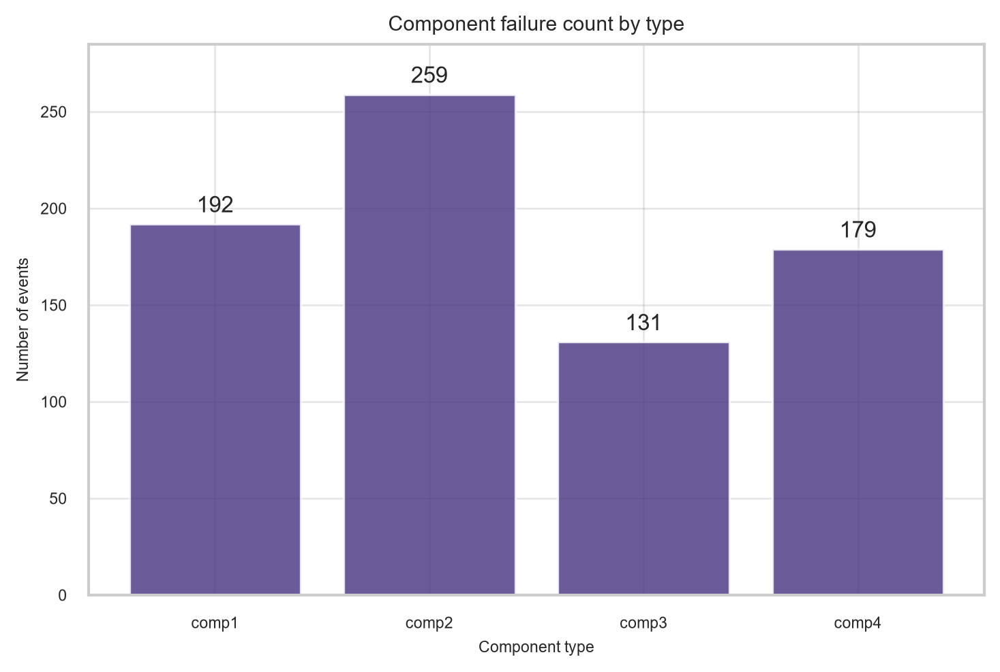

In [53]:
# compare failure counts across component types
plot_event_counts(
    summary=failures_summary,
    title='Component failure count by type',
    xlabel='Component type'
)

Failure counts differ across component types. Comp2 accounts for the largest share, with 259 events (34.03%), while comp3 has the fewest failures, with 131 events (17.21%). Comp1 and comp4 have intermediate counts. These differences indicate unequal representation of component failure events

Aggregate failure events into daily counts across all machines, including days without failures from telemetry. Exclude days with incomplete telemetry coverage and use trailing seven-day averages to highlight changes in failure frequency

In [54]:
# calculate daily failure counts and rolling averages
(
    daily_failures,
    complete_days,
    daily_failures_total,
    weekly_failures_total,
    weekly_failures_by_type
) = make_daily_event_counts(
    events=failures, 
    telemetry=telemetry, 
    event_col='failure', 
    event_types=FAILURE_TYPES
)

print(f'Complete days: {complete_days.sum()} / {len(complete_days)}')

Complete days: 364 / 366


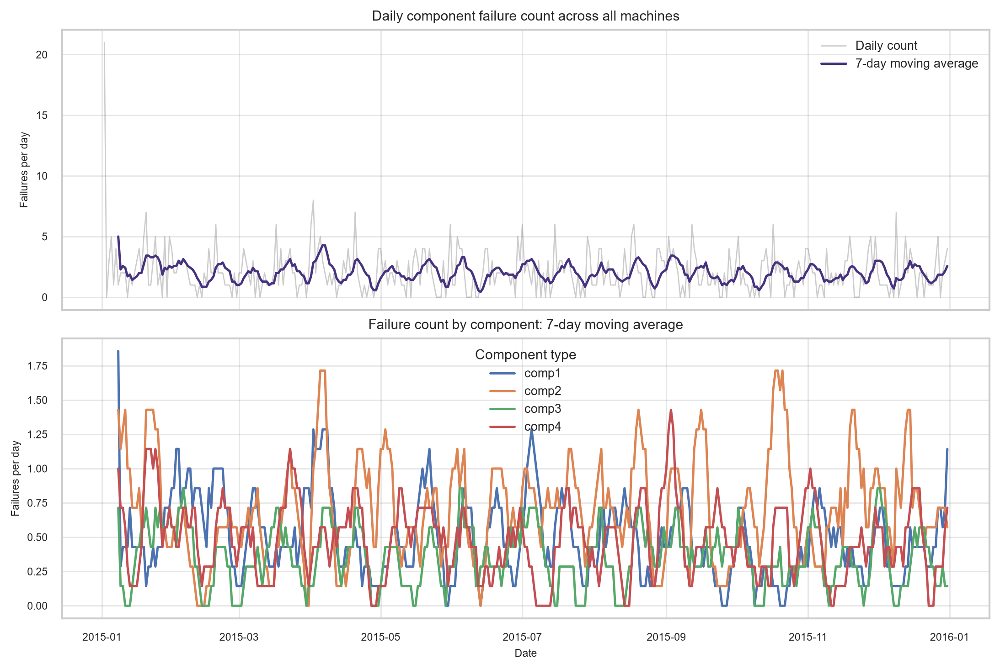

In [55]:
# examine daily failure counts and rolling averages
plot_daily_event_trends(
    daily_total=daily_failures_total,
    rolling_total=weekly_failures_total,
    rolling_by_type=weekly_failures_by_type,
    title='Daily component failure count across all machines',
    type_title='Failure count by component: 7-day moving average',
    ylabel='Failures per day',
    type_label='Component type'
)

Across most of the observation period, the seven-day moving average remains around 1–3 component failures per day across the fleet, with no clear sustained trend. A pronounced spike exceeding 20 failures occurs near the beginning of January and requires separate inspection. Comp2 frequently shows higher failure counts than the other components, although the relative ordering varies over time

In [56]:
# summarize daily failure count distributions
daily_failures_summary = summarize_daily_events(
    daily_counts=daily_failures, 
    complete_days=complete_days
)

display(daily_failures_summary.round(2))

,mean,median,std,p95,max,zero_days,zero_days_pct
failure,,,,,,,
comp1,0.53,0.0,0.89,2.0,11,218,59.89
comp2,0.71,0.0,0.92,3.0,5,187,51.37
comp3,0.36,0.0,0.62,2.0,4,256,70.33
comp4,0.49,0.0,0.68,2.0,3,220,60.44


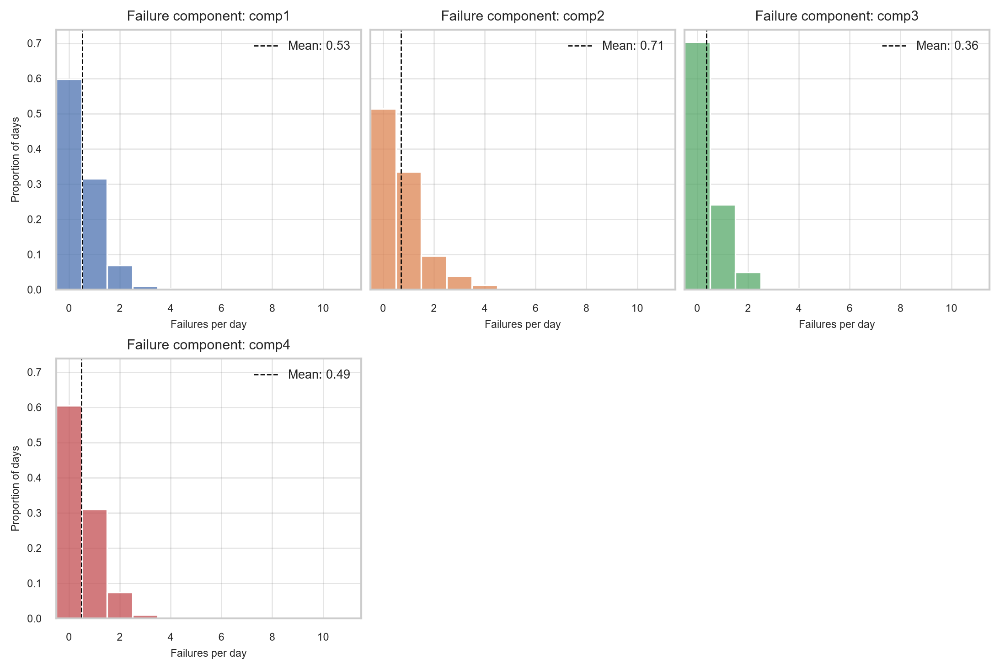

In [57]:
# compare daily failure count distributions
plot_daily_event_distributions(
    daily_counts=daily_failures,
    complete_days=complete_days,
    xlabel='Failures per day',
    title_prefix='Failure component',
    ncols=3
)

Daily component failure counts across the fleet are strongly right-skewed, with zero failures being the most common outcome for every component type. Most observations contain zero or one failure per day. Comp2 has the highest mean frequency at 0.71 failures per day, while comp3 has the lowest at 0.36. Rare high-count days contribute to the distribution tails but are barely visible

In [58]:
# summarize component failure counts by machine
failures_per_machine, failures_machine_totals = summarize_events_by_machine(
    events=failures, 
    machines=machines, 
    event_col='failure', 
    event_types=FAILURE_TYPES, 
    total_name='total_failures'
)

# show top-10 machines
display(
    failures_per_machine
    .assign(total_failures=failures_machine_totals)
    .head(10)
)

failure,comp1,comp2,comp3,comp4,total_failures
machineID,,,,,
99,2,6,6,5,19
98,4,4,5,3,16
17,3,4,4,4,15
22,2,4,5,4,15
37,1,3,4,6,14
83,4,4,0,6,14
13,3,3,3,4,13
16,4,3,6,0,13
20,2,4,3,4,13


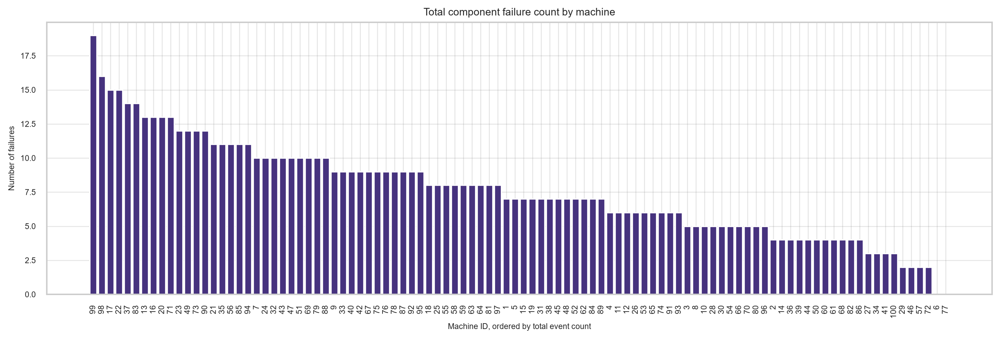

In [59]:
# compare total failure counts across machines
plot_machine_event_counts(
    totals=failures_machine_totals,
    title='Total component failure count by machine',
    ylabel='Number of failures'
)

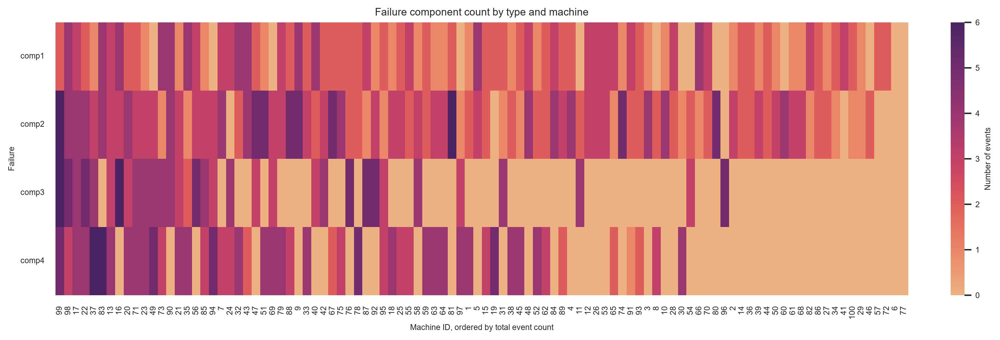

In [60]:
# compare failure counts across machines
plot_machine_event_heatmap(
    counts=failures_per_machine,
    title='Failure component count by type and machine',
    ylabel='Failure'
)

### Machine Fleet Analysis

In [61]:
# sort and display machines
machines = machines.sort_values(['machineID'])
display(machines)

,machineID,model,age
0,1,model3,18
1,2,model4,7
2,3,model3,8
3,4,model3,7
4,5,model3,2
...,...,...,...
95,96,model2,10
96,97,model2,14
97,98,model2,20
98,99,model1,14


In [62]:
# summarize fleet composition and machine age by model
machine_summary = (
    machines.groupby('model').agg(
        machine_count=('machineID', 'nunique'),
        mean_age=('age', 'mean'),
        median_age=('age', 'median'),
        min_age=('age', 'min'),
        max_age=('age', 'max')
    )
    .sort_values('machine_count', ascending=False, kind='stable')
)

total_machines = machines['machineID'].nunique()

machine_summary['machine_share_pct'] = (
    machine_summary['machine_count']
    .div(total_machines if total_machines else np.nan)
    .mul(100)
)

display(machine_summary.round(2))

,machine_count,mean_age,median_age,min_age,max_age,machine_share_pct
model,,,,,,
model3,35,12.03,14.0,1,20,35.0
model4,32,9.34,9.5,0,20,32.0
model2,17,12.76,14.0,2,20,17.0
model1,16,12.25,14.0,2,20,16.0


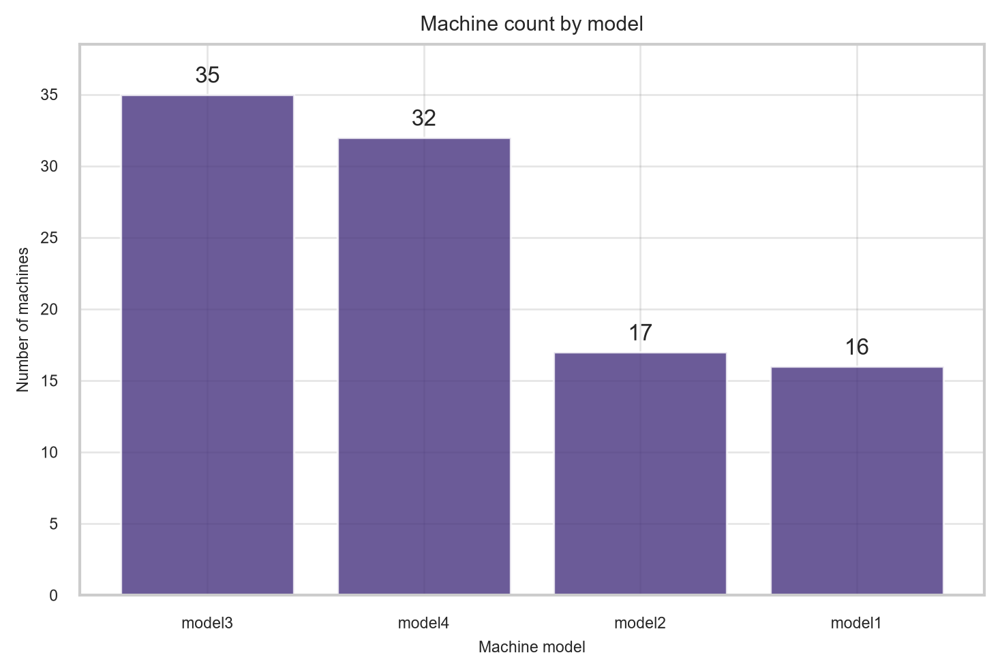

In [63]:
# compare machine counts across models
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')

bars = ax.bar(machine_summary.index.astype(str), machine_summary['machine_count'], alpha=0.8)

ax.bar_label(bars, fmt='%.0f', padding=3, fontsize=10)
ax.set(title='Machine count by model', xlabel='Machine model', ylabel='Number of machines')
ax.margins(y=0.1)
ax.set_axisbelow(True)

plt.show()

The fleet contains 100 machines across four models. Model3 and model4 are the most common, accounting for 35% and 32% of machines, respectively. Model2 and model1 represent the remaining 17% and 16%

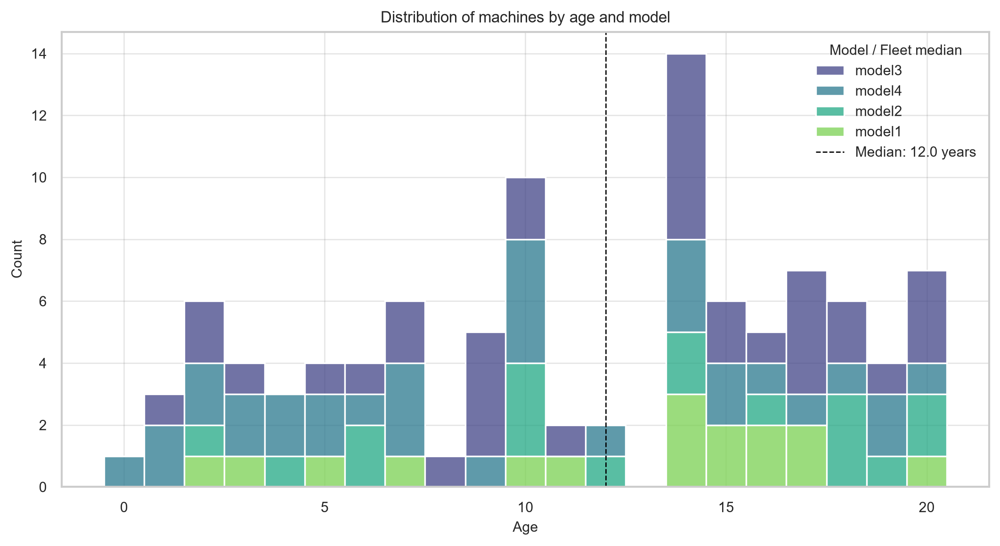

In [64]:
# examine the age distribution across the fleet
fig, ax = plt.subplots(figsize=(9, 5))

age_values = machines['age'].dropna()
median_age = age_values.median()
bins = np.arange(np.floor(age_values.min()) - 0.5, np.ceil(age_values.max()) + 1.5, 1)

sns.histplot(
    data=machines, x='age', hue='model',
    multiple='stack', bins=bins, kde=False,
    palette='viridis', edgecolor='white',
    ax=ax
)

legend = ax.get_legend()
handles = [entry for entry in legend.legend_handles]
labels = [text.get_text() for text in legend.get_texts()]

median_line = ax.axvline(
    median_age,
    color='black', linestyle='--', linewidth=0.8,
    label=f'Median: {median_age:.1f} years'
)

ax.legend(
    handles=[*handles, median_line],
    labels=[*labels, median_line.get_label()],
    title='Model / Fleet median',
    fontsize=9, title_fontsize=9
)

ax.set_title('Distribution of machines by age and model', fontsize=10)
ax.tick_params(axis='both', which='major', labelsize=9)
ax.set_xlabel('Age', fontsize=9)
ax.set_ylabel('Count', fontsize=9)

fig.tight_layout()
plt.show()

Machine ages range from 0 to 20 years, with a fleet median of 12 years. The largest individual age group is 14 years, with another noticeable peak at 10 years. The stacked bars show how each model contributes to the fleet age distribution

## Feature Engineering

In [65]:
# set common feature constants
KEYS = ['machineID', 'datetime']
SENSORS = ['volt', 'rotate', 'pressure', 'vibration']
ERROR_TYPES = ['error1', 'error2', 'error3', 'error4', 'error5']
COMPONENTS = ['comp1', 'comp2', 'comp3', 'comp4']
WINDOW_HOURS = (3, 12, 24)

### Telemetry Rolling Features

Calculate historical sensor features over 3-, 12-, and 24-hour windows for each machine. Each window excludes the current timestamp and requires complete hourly measurements. Compute the mean, standard deviation, and difference between the last and first measurements within each window

In [66]:
def make_telemetry_features(telemetry, sensors, windows=(3, 12, 24)):
    """Calculate historical features on a regular hourly grid"""

    # validate missing machine IDs or timestamps
    if telemetry[KEYS].isna().any().any():
        raise ValueError('Missing machine IDs or timestamps')

    # vakidate machine–timestamp duplicates 
    if telemetry.duplicated(KEYS).any():
        raise ValueError('Duplicate machine–timestamp keys')

    data = telemetry.sort_values(KEYS)
    
    # validate timeseries regularity
    time_steps = data.groupby('machineID')['datetime'].diff().dropna()
    if time_steps.ne(pd.Timedelta('1h')).any():
        raise ValueError('Expected a regular hourly grid for each machine')

    parts = []

    # make rolling-window features for each machine
    for machine_id, machine_data in data.groupby('machineID', sort=False):

        values = (
            machine_data
            .set_index('datetime')[sensors]
            .replace([np.inf, -np.inf], np.nan)
        )

        blocks = []

        # make rolling-window features for each window
        for hours in windows:

            # require all hourly measurements in [t - window, t)
            # exclude the last value (closed='left') to prevent data leakage
            stats = values.rolling(window=f'{hours}h', closed='left', min_periods=hours).agg(['mean', 'std'])
            stats.columns = [f'{sensor}_{stat}_{hours}h' for sensor, stat in stats.columns]

            # difference between the last and first window values
            diffs = values.shift(1) - values.shift(hours)
            diffs.columns = [f'{sensor}_diff_{hours}h' for sensor in sensors]

            blocks.extend([stats, diffs])

        features = pd.concat(blocks, axis=1).dropna()
        features.insert(0, 'machineID', machine_id)

        parts.append(features.reset_index())

    if not parts:
        raise ValueError('Telemetry is empty')

    return pd.concat(parts, ignore_index=True)

In [67]:
# make telemetry features
telemetry_features = make_telemetry_features(
    telemetry=telemetry,
    sensors=SENSORS,
    windows=WINDOW_HOURS
)

In [68]:
# print telemetry features list
print(f'List of {len(telemetry_features.columns) - len(KEYS)} Telemetry Features:\n------------')
for i, col in enumerate([col for col in telemetry_features.columns if col not in KEYS], start=1):
    print(f'{col:<25}', end='')
    if i % 6 == 0:
        print()

List of 36 Telemetry Features:
------------
volt_mean_3h             volt_std_3h              rotate_mean_3h           rotate_std_3h            pressure_mean_3h         pressure_std_3h          
vibration_mean_3h        vibration_std_3h         volt_diff_3h             rotate_diff_3h           pressure_diff_3h         vibration_diff_3h        
volt_mean_12h            volt_std_12h             rotate_mean_12h          rotate_std_12h           pressure_mean_12h        pressure_std_12h         
vibration_mean_12h       vibration_std_12h        volt_diff_12h            rotate_diff_12h          pressure_diff_12h        vibration_diff_12h       
volt_mean_24h            volt_std_24h             rotate_mean_24h          rotate_std_24h           pressure_mean_24h        pressure_std_24h         
vibration_mean_24h       vibration_std_24h        volt_diff_24h            rotate_diff_24h          pressure_diff_24h        vibration_diff_24h       


In [69]:
# display 3h-rolling window telemetry features
columns_3h = KEYS + [col for col in telemetry_features.columns if col.endswith('_3h')]
display(telemetry_features[columns_3h])

,machineID,datetime,volt_mean_3h,volt_std_3h,rotate_mean_3h,rotate_std_3h,pressure_mean_3h,pressure_std_3h,vibration_mean_3h,vibration_std_3h,volt_diff_3h,rotate_diff_3h,pressure_diff_3h,vibration_diff_3h
0,1,2015-01-02 06:00:00,180.133784,21.322735,440.608320,48.770512,94.137969,2.135684,41.551544,10.037208,22.986121,72.966906,1.000158,12.573959
1,1,2015-01-02 07:00:00,193.164359,10.459846,448.652619,46.294659,101.438946,11.281152,38.133459,12.407322,-3.509305,43.707997,17.806574,-2.989173
2,1,2015-01-02 08:00:00,183.273847,13.197149,442.455956,55.701766,103.718215,10.455653,39.226702,11.794329,-10.056627,-111.131996,9.934003,-16.559310
3,1,2015-01-02 09:00:00,176.364293,18.952210,439.349655,51.329636,101.553209,13.789279,36.105580,6.737739,-36.834264,39.515109,-27.397788,13.464845
4,1,2015-01-02 10:00:00,159.676811,11.972868,430.571937,51.632304,100.242184,12.041639,37.664039,4.682870,-23.900216,35.964830,7.035691,-1.593524
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
873695,100,2016-01-01 02:00:00,161.221580,8.383148,444.916550,33.948705,107.391436,8.725796,45.212821,1.810018,10.560636,67.242279,-15.836605,0.416045
873696,100,2016-01-01 03:00:00,170.306956,8.457322,438.653616,43.021553,102.346227,0.785721,47.481232,3.198928,10.698123,-44.261285,-0.867518,3.482940
873697,100,2016-01-01 04:00:00,177.266129,13.568463,440.894903,43.260932,100.687019,2.198731,43.425922,7.868190,26.874886,-35.045936,-3.409128,-9.259682
873698,100,2016-01-01 05:00:00,187.179710,6.855798,429.749108,29.911451,98.201386,4.078979,44.736524,8.415672,13.045253,52.593697,-8.157878,-2.457380


In [70]:
# display 12h-rolling window telemetry features
columns_12h = KEYS + [col for col in telemetry_features.columns if col.endswith('_12h')]
display(telemetry_features[columns_12h])

,machineID,datetime,volt_mean_12h,volt_std_12h,rotate_mean_12h,rotate_std_12h,pressure_mean_12h,pressure_std_12h,vibration_mean_12h,vibration_std_12h,volt_diff_12h,rotate_diff_12h,pressure_diff_12h,vibration_diff_12h
0,1,2015-01-02 06:00:00,172.500004,14.150081,460.425183,44.611934,91.150092,5.159011,41.579686,6.078464,27.904030,5.105037,7.426850,8.247322
1,1,2015-01-02 07:00:00,176.167473,14.436868,456.781102,43.693079,93.510893,8.187355,40.364612,6.925343,14.624011,28.744695,20.857107,-11.839525
2,1,2015-01-02 08:00:00,175.205955,14.343326,453.984994,47.310423,94.334922,8.668011,39.900393,7.037820,0.865457,-17.815225,10.137506,-3.943317
3,1,2015-01-02 09:00:00,174.388740,14.914063,460.984817,45.159243,93.810629,8.926944,40.171445,7.093491,-21.938249,-15.459917,1.181658,-8.028977
4,1,2015-01-02 10:00:00,171.458205,16.547915,454.209135,44.554837,95.864493,9.708048,38.769908,6.380514,-4.035004,-24.311865,16.161613,-7.916610
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
873695,100,2016-01-01 02:00:00,166.520359,16.215560,453.169818,69.867025,103.804807,9.443227,40.287631,7.003811,2.478124,124.591332,-10.570953,6.194200
873696,100,2016-01-01 03:00:00,168.118160,16.485495,456.383173,65.792865,102.982310,9.071803,41.336247,7.579317,1.911199,6.731889,-1.648403,-0.060269
873697,100,2016-01-01 04:00:00,169.125709,17.453844,461.192925,62.400675,102.502434,9.168380,40.027152,7.133608,24.888385,-2.686603,-1.582524,-8.793229
873698,100,2016-01-01 05:00:00,171.438563,18.618331,461.103088,62.420763,102.033242,9.460712,40.393674,7.457245,1.463286,-89.972849,-11.714395,2.523296


In [71]:
# display 24h-rolling window telemetry features
columns_24h = KEYS + [col for col in telemetry_features.columns if col.endswith('_24h')]
display(telemetry_features[columns_24h])

,machineID,datetime,volt_mean_24h,volt_std_24h,rotate_mean_24h,rotate_std_24h,pressure_mean_24h,pressure_std_24h,vibration_mean_24h,vibration_std_24h,volt_diff_24h,rotate_diff_24h,pressure_diff_24h,vibration_diff_24h
0,1,2015-01-02 06:00:00,169.733809,11.233120,445.179865,48.717395,96.797113,10.079880,40.385160,5.853209,5.039669,77.273880,-19.638645,7.268190
1,1,2015-01-02 07:00:00,170.614862,12.519402,446.364859,48.385076,96.849785,10.171540,39.736826,6.163231,34.483902,44.196458,18.881535,-13.886308
2,1,2015-01-02 08:00:00,170.961598,12.410607,445.610629,49.228285,97.179484,10.252470,39.419434,6.161772,0.210992,-142.703864,28.135388,1.617719
3,1,2015-01-02 09:00:00,170.525721,12.591948,443.906847,46.930282,97.667249,9.406795,39.786670,6.098173,-1.933973,140.309721,-22.304289,1.870365
4,1,2015-01-02 10:00:00,169.893965,13.370357,447.009407,42.432317,97.715600,9.471669,39.498374,6.195076,-10.309343,-14.766081,-1.477664,8.212531
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
873695,100,2016-01-01 02:00:00,169.315176,16.909035,465.030065,64.335540,101.931634,9.236972,39.422921,5.706229,14.616153,18.944809,-13.100502,6.399441
873696,100,2016-01-01 03:00:00,170.619827,16.403499,462.234803,65.897332,101.414987,8.830133,39.955780,6.146110,43.074620,-78.331730,3.671895,15.848287
873697,100,2016-01-01 04:00:00,172.838745,15.119775,461.095362,65.929509,101.396728,8.836617,39.964090,6.139142,19.692451,-131.366497,-4.985876,-2.239646
873698,100,2016-01-01 05:00:00,173.778674,15.623554,455.688781,61.106287,101.020326,8.949630,40.420416,6.341081,29.248636,26.551502,0.313262,-0.332063


### Errors Rolling Features

Count errors of each type over the preceding 3, 12, and 24 hours for each machine. Align events to the original telemetry grid and fill observed hours without errors with zeros before calculating rolling counts. Exclude the current timestamp and retain only observations with complete historical windows

In [72]:
def make_error_features(telemetry, errors, error_types, windows=(3, 12, 24)):
    """Count historical errors on a regular hourly grid"""

    # validate the original observation grid
    if telemetry[KEYS].isna().any().any():
        raise ValueError('Missing machine IDs or timestamps in telemetry')

    # validate machine–timestamp duplicates 
    if telemetry.duplicated(KEYS).any():
        raise ValueError('Duplicate machine–timestamp keys in telemetry')

    # get original telemetry observation grid
    grid = telemetry[KEYS].sort_values(KEYS)
    if grid.empty:
        raise ValueError('Telemetry is empty')

    # validate timeseries regularity
    time_steps = grid.groupby('machineID')['datetime'].diff().dropna()
    if time_steps.ne(pd.Timedelta('1h')).any():
        raise ValueError('Expected a regular hourly grid for each machine')

    # validate error records before aligning them to the grid
    if errors[KEYS + ['errorID']].isna().any().any():
        raise ValueError('Missing values in error event keys')

    # count events and fill hours without errors with zeros
    counts = (
        errors
        .groupby(KEYS + ['errorID'])
        .size()
        .unstack('errorID', fill_value=0)
        .reindex(
            index=pd.MultiIndex.from_frame(grid),
            columns=error_types,
            fill_value=0
        )
    )

    parts = []

    # make rolling-window features for each machine
    for machine_id, machine_data in counts.reset_index().groupby('machineID', sort=False):
        
        values = machine_data.set_index('datetime')[error_types]
        blocks = []

        # make rolling-window features for each window
        for hours in windows:

            stats = values.rolling(window=f'{hours}h', closed='left', min_periods=hours).sum()
            stats.columns = [f'{error}_cnt_{hours}h' for error in error_types]
            
            blocks.append(stats)

        features = pd.concat(blocks, axis=1).dropna().astype('int64')
        features.insert(0, 'machineID', machine_id)
        
        parts.append(features.reset_index())

    return pd.concat(parts, ignore_index=True)

In [73]:
# make error features
error_features = make_error_features(
    telemetry=telemetry,
    errors=errors,
    error_types=ERROR_TYPES,
    windows=WINDOW_HOURS
)

In [74]:
# print error features list
print(f'List of {len(error_features.columns) - len(KEYS)} Error Features:\n------------')
for i, col in enumerate([col for col in error_features.columns if col not in KEYS], start=1):
    print(f'{col:<25}', end='')
    if i % 5 == 0:
        print()

List of 15 Error Features:
------------
error1_cnt_3h            error2_cnt_3h            error3_cnt_3h            error4_cnt_3h            error5_cnt_3h            
error1_cnt_12h           error2_cnt_12h           error3_cnt_12h           error4_cnt_12h           error5_cnt_12h           
error1_cnt_24h           error2_cnt_24h           error3_cnt_24h           error4_cnt_24h           error5_cnt_24h           


In [75]:
# display 3h-rolling window error features
columns_3h = KEYS + [col for col in error_features.columns if col.endswith('_3h')]
display(error_features[columns_3h])

,machineID,datetime,error1_cnt_3h,error2_cnt_3h,error3_cnt_3h,error4_cnt_3h,error5_cnt_3h
0,1,2015-01-02 06:00:00,0,0,0,0,0
1,1,2015-01-02 07:00:00,0,0,0,0,0
2,1,2015-01-02 08:00:00,0,0,0,0,0
3,1,2015-01-02 09:00:00,0,0,0,0,0
4,1,2015-01-02 10:00:00,0,0,0,0,0
...,...,...,...,...,...,...,...
873695,100,2016-01-01 02:00:00,0,0,0,0,0
873696,100,2016-01-01 03:00:00,0,0,0,0,0
873697,100,2016-01-01 04:00:00,0,0,0,0,0
873698,100,2016-01-01 05:00:00,0,0,0,0,0


In [76]:
# display 12h-rolling window error features
columns_12h = KEYS + [col for col in error_features.columns if col.endswith('_12h')]
display(error_features[columns_12h])

,machineID,datetime,error1_cnt_12h,error2_cnt_12h,error3_cnt_12h,error4_cnt_12h,error5_cnt_12h
0,1,2015-01-02 06:00:00,0,0,0,0,0
1,1,2015-01-02 07:00:00,0,0,0,0,0
2,1,2015-01-02 08:00:00,0,0,0,0,0
3,1,2015-01-02 09:00:00,0,0,0,0,0
4,1,2015-01-02 10:00:00,0,0,0,0,0
...,...,...,...,...,...,...,...
873695,100,2016-01-01 02:00:00,0,0,0,0,0
873696,100,2016-01-01 03:00:00,0,0,0,0,0
873697,100,2016-01-01 04:00:00,0,0,0,0,0
873698,100,2016-01-01 05:00:00,0,0,0,0,0


In [77]:
# display 24h-rolling window error features
columns_24h = KEYS + [col for col in error_features.columns if col.endswith('_24h')]
display(error_features[columns_24h])

,machineID,datetime,error1_cnt_24h,error2_cnt_24h,error3_cnt_24h,error4_cnt_24h,error5_cnt_24h
0,1,2015-01-02 06:00:00,0,0,0,0,0
1,1,2015-01-02 07:00:00,0,0,0,0,0
2,1,2015-01-02 08:00:00,0,0,0,0,0
3,1,2015-01-02 09:00:00,0,0,0,0,0
4,1,2015-01-02 10:00:00,0,0,0,0,0
...,...,...,...,...,...,...,...
873695,100,2016-01-01 02:00:00,0,0,0,0,0
873696,100,2016-01-01 03:00:00,0,0,0,0,0
873697,100,2016-01-01 04:00:00,0,0,0,0,0
873698,100,2016-01-01 05:00:00,0,0,0,0,0


### Maintenance Features

For each observation, identify the most recent replacement of each component on the same machine and calculate the elapsed time in days. Use the full maintenance history, including records preceding telemetry, and exclude replacements at the current timestamp. Preserve missing values when no earlier replacement is known

In [78]:
def make_maintenance_features(observations, maint, components, include_current=False):
    """Calculate time since the last known component replacement"""

    # validate observation and maintenance keys
    if observations[KEYS].isna().any().any():
        raise ValueError('Missing observation keys')

    # validate machine–timestamp duplicates 
    if observations.duplicated(KEYS).any():
        raise ValueError('Duplicate observation keys')

    # validate maintenance keys
    if maint[KEYS + ['comp']].isna().any().any():
        raise ValueError('Missing maintenance event keys')

    # merge_asof requires globally sorted timestamps
    base = (
        observations[KEYS]
        .sort_values('datetime')
        .reset_index(drop=True)
    )

    features = base.copy()

    # for each replaced component calculate days since replacement
    for component in components:
        feature_name = f'{component}_days_since_replacement'

        replacements = (
            maint.loc[maint['comp'].eq(component), KEYS]
            .rename(columns={'datetime': 'last_replacement'})
            .sort_values('last_replacement')
        )

        # unknown replacement history remains missing
        if replacements.empty or base.empty:
            features[feature_name] = np.nan
            continue

        matched = pd.merge_asof(
            base,
            replacements,
            left_on='datetime',
            right_on='last_replacement',
            by='machineID',
            direction='backward',
            allow_exact_matches=include_current,
        )

        features[feature_name] = (
            (matched['datetime'] - matched['last_replacement'])
            .dt.total_seconds()
            .div(86_400)
            .to_numpy()
        )

    return (
        features
        .sort_values(KEYS)
        .reset_index(drop=True)
    )

In [79]:
# make maintenance features
maint_features = make_maintenance_features(
    observations=telemetry_features,
    maint=maint,
    components=COMPONENTS
)

display(maint_features)

,machineID,datetime,comp1_days_since_replacement,comp2_days_since_replacement,comp3_days_since_replacement,comp4_days_since_replacement
0,1,2015-01-02 06:00:00,20.000000,215.000000,155.000000,170.000000
1,1,2015-01-02 07:00:00,20.041667,215.041667,155.041667,170.041667
2,1,2015-01-02 08:00:00,20.083333,215.083333,155.083333,170.083333
3,1,2015-01-02 09:00:00,20.125000,215.125000,155.125000,170.125000
4,1,2015-01-02 10:00:00,20.166667,215.166667,155.166667,170.166667
...,...,...,...,...,...,...
873695,100,2016-01-01 02:00:00,82.833333,7.833333,82.833333,52.833333
873696,100,2016-01-01 03:00:00,82.875000,7.875000,82.875000,52.875000
873697,100,2016-01-01 04:00:00,82.916667,7.916667,82.916667,52.916667
873698,100,2016-01-01 05:00:00,82.958333,7.958333,82.958333,52.958333


In [80]:
# check how often previous replacement history is unavailable
display(
    maint_features
    .drop(columns=KEYS)
    .isna().sum()
    .rename('missing_count')
    .to_frame()
)

,missing_count
comp1_days_since_replacement,0
comp2_days_since_replacement,0
comp3_days_since_replacement,0
comp4_days_since_replacement,0


### Assembling Features

Combine telemetry statistics, rolling error counts, and time-since-replacement features by machine and timestamp. Add machine model and age, validate merge cardinality, and verify that every observation has matching feature and metadata records. Preserve missing values representing unknown replacement history

In [81]:
def assemble_features(telemetry_features, error_features, maint_features, machines):
    """Combine historical features and machine metadata"""

    features = telemetry_features.copy()

    # attach one feature row per machine and timestamp
    for name, frame in [
        ('errors', error_features),
        ('maintenance', maint_features)
    ]:
        if frame[KEYS].isna().any().any():
            raise ValueError(f'Missing {name} feature keys')

        features = features.merge(
            frame,
            on=KEYS,
            how='left',
            validate='one_to_one',
            indicator=True,
            suffixes=(False, False)
        )

        missing = features['_merge'].eq('left_only')
        if missing.any():
            raise ValueError(f'Missing {name} feature rows: {missing.sum()}')

        features = features.drop(columns='_merge')

    # attach one metadata record per machine.
    metadata = machines[['machineID', 'model', 'age']]

    if metadata['machineID'].isna().any():
        raise ValueError('Missing machine IDs in metadata.')

    features = features.merge(
        metadata,
        on='machineID',
        how='left',
        validate='many_to_one',
        indicator=True,
        suffixes=(False, False)
    )

    if features['_merge'].eq('left_only').any():
        raise ValueError('Machine metadata is unavailable for some observations')

    return (
        features
        .drop(columns='_merge')
        .sort_values(KEYS)
        .reset_index(drop=True)
    )

In [82]:
# assembling features into one dataframe
final_features = assemble_features(
    telemetry_features=telemetry_features,
    error_features=error_features,
    maint_features=maint_features,
    machines=machines
)

print('Number of observations:', len(final_features))
print('Number of features:', len(final_features.columns) - len(KEYS))

Number of observations: 873700
Number of features: 57


In [83]:
# print total features list
print(f'List of {len(final_features.columns) - len(KEYS)} Final Features:\n------------')
for i, col in enumerate([col for col in final_features.columns if col not in KEYS], start=1):
    print(f'{col:<35}', end='')
    if i % 7 == 0:
        print()

List of 57 Final Features:
------------
volt_mean_3h                       volt_std_3h                        rotate_mean_3h                     rotate_std_3h                      pressure_mean_3h                   pressure_std_3h                    vibration_mean_3h                  
vibration_std_3h                   volt_diff_3h                       rotate_diff_3h                     pressure_diff_3h                   vibration_diff_3h                  volt_mean_12h                      volt_std_12h                       
rotate_mean_12h                    rotate_std_12h                     pressure_mean_12h                  pressure_std_12h                   vibration_mean_12h                 vibration_std_12h                  volt_diff_12h                      
rotate_diff_12h                    pressure_diff_12h                  vibration_diff_12h                 volt_mean_24h                      volt_std_24h                       rotate_mean_24h                    rotate_std_2

In [84]:
# inspect missing feature values without removing observations
missing_summary = final_features.isna().sum().rename('missing_count').to_frame()
display(missing_summary.loc[missing_summary['missing_count'].gt(0)])

,missing_count


## Labeling

Assign each observation the component associated with the nearest failure within the next 24 hours, excluding failures at the current timestamp. Assign none when no event occurs within a fully observed horizon. Exclude observations whose nearest event involves simultaneous failures of multiple components, and retain future-event details separately for auditing

In [85]:
def label_next_failure(features, failures, observation_end, components, horizon='24h'):
    """Label the nearest future failure, excluding ambiguous targets"""
    
    horizon = pd.Timedelta(horizon)

    # validate target feature
    if 'failure' in features.columns:
        raise ValueError('Features already contain a target')

    # validate missing or duplicate observation keys
    if features[KEYS].isna().any().any() or features.duplicated(KEYS).any():
        raise ValueError('Missing or duplicate observation keys')

    # validate failure events
    if failures[KEYS + ['failure']].isna().any().any():
        raise ValueError('Missing failure event keys')

    # combine components failing on the same machine at the same time
    events = (
        failures
        .groupby(KEYS)['failure']
        .agg(lambda values: tuple(sorted(set(values))))
        .rename('next_components')
        .reset_index()
        .rename(columns={'datetime': 'next_failure_datetime'})
    )

    # find the nearest strictly future event within the horizon
    audit = pd.merge_asof(
        features[KEYS].sort_values('datetime'),
        events.sort_values('next_failure_datetime'),
        left_on='datetime',
        right_on='next_failure_datetime',
        by='machineID',
        direction='forward',
        tolerance=horizon,
        allow_exact_matches=False
    )

    row_observation_end = audit['machineID'].map(observation_end)

    # validate missing observation end
    if row_observation_end.isna().any():
        raise ValueError('Missing observation end for some machines')

    full_horizon = audit['datetime'] + horizon <= row_observation_end

    # define assigning label function
    def assign_label(component_tuple):
        if not isinstance(component_tuple, tuple):
            return 'none'
        if len(component_tuple) == 1:
            return component_tuple[0]
        return 'ambiguous'

    audit['failure'] = audit['next_components'].map(assign_label)

    # record why an observation is retained or excluded
    audit['label_status'] = 'labeled'
    audit.loc[audit['failure'].eq('ambiguous'), 'label_status'] = 'simultaneous_failure'
    audit.loc[~full_horizon, 'label_status'] = 'incomplete_horizon'

    labels = audit.loc[audit['label_status'].eq('labeled'), KEYS + ['failure']]

    # future-event details remain exclusively in the audit table
    labeled = features.merge(
        labels,
        on=KEYS,
        how='inner',
        validate='one_to_one'
    ).sort_values(KEYS).reset_index(drop=True)

    audit = audit.sort_values(KEYS).reset_index(drop=True)

    return labeled, audit

In [86]:
# make next failure labels
HORIZON = pd.Timedelta('24h')
observation_end = telemetry.groupby('machineID')['datetime'].max()

labeled_features, labeling_audit = label_next_failure(
    features=final_features,
    failures=failures,
    observation_end=observation_end,
    components=COMPONENTS,
    horizon=HORIZON
)

In [87]:
# summarize retained and excluded hourly observations
display(
    labeling_audit['label_status']
    .value_counts()
    .rename_axis('label_status')
    .rename('observation_count')
    .to_frame()
)

,observation_count
label_status,
labeled,870316
incomplete_horizon,2400
simultaneous_failure,984


In [88]:
# inspect the resulting target distribution
CLASSES = ['none', 'comp1', 'comp2', 'comp3', 'comp4']

class_summary = (
    labeled_features['failure']
    .value_counts()
    .reindex(CLASSES, fill_value=0)
    .rename('observation_count')
    .to_frame()
)
class_summary['share_pct'] = (
    class_summary['observation_count']
    .div(len(labeled_features) if len(labeled_features) else np.nan)
    .mul(100)
)

display(class_summary.round(2))

,observation_count,share_pct
failure,,
none,854524,98.19
comp1,3888,0.45
comp2,5496,0.63
comp3,2760,0.32
comp4,3648,0.42


Labeling retains 870,316 hourly observations. A further 2,400 observations are excluded because their future horizons are incomplete, and 984 because their nearest failure events involve multiple components simultaneously. The target is strongly imbalanced: none accounts for 98.19% of retained observations, while component failure classes together account for 1.81%. Model evaluation therefore requires class-specific and event-level metrics rather than accuracy alone

## Data Split

Split labeled observations chronologically into training, validation, and test sets. Exclude observations whose 24-hour target horizons reach the next evaluation period. Preserve historical data used to calculate features, and inspect class representation within each split

In [89]:
HORIZON = pd.Timedelta('24h')
VALID_START = pd.Timestamp('2015-08-01')
TEST_START = pd.Timestamp('2015-10-01')

# split observations chronologically with 24-hour target-horizon gaps
timestamps = labeled_features['datetime']
horizon_end = timestamps + HORIZON

train_mask = horizon_end < VALID_START
valid_mask = (timestamps >= VALID_START) & (horizon_end < TEST_START)
test_mask = timestamps >= TEST_START

train = labeled_features.loc[train_mask].copy()
valid = labeled_features.loc[valid_mask].copy()
test = labeled_features.loc[test_mask].copy()

# retain excluded observations for inspection
gap_rows = labeled_features.loc[~(train_mask | valid_mask | test_mask)].copy()

splits = {
    'train': train,
    'valid': valid,
    'test': test
}

In [90]:
# inspect split sizes and observation periods
split_summary = pd.DataFrame({
    name: {
        'observation_count': len(frame),
        'machine_count': frame['machineID'].nunique(),
        'first_observation': frame['datetime'].min(),
        'last_observation': frame['datetime'].max()
    }
    for name, frame in splits.items()
}).T

display(split_summary)

,observation_count,machine_count,first_observation,last_observation
train,502872,100,2015-01-02 06:00:00,2015-07-30 23:00:00
valid,143760,100,2015-08-01 00:00:00,2015-09-29 23:00:00
test,218884,100,2015-10-01 00:00:00,2015-12-31 06:00:00


In [91]:
# inspect excluded temporal gaps
print(f'Observations excluded by temporal gaps (2 gaps)*(24 hours)*(100 machines): {len(gap_rows)}')

Observations excluded by temporal gaps (2 gaps)*(24 hours)*(100 machines): 4800


In [92]:
# compare target counts and proportions across temporal splits
class_distribution = pd.DataFrame({
    name: frame['failure'].value_counts()
    for name, frame in splits.items()
}).reindex(CLASSES).fillna(0).astype(int)

# calculate target proportions for each split
for name in splits:
    class_distribution[f'{name}_share_pct'] = (
        class_distribution[name]
        .div(class_distribution[name].sum())
        .mul(100)
        .round(2)
    )

display(class_distribution)

,train,valid,test,train_share_pct,valid_share_pct,test_share_pct
failure,,,,,,
none,493446,141312,215050,98.13,98.30,98.25
comp1,2520,552,798,0.50,0.38,0.36
comp2,3096,774,1590,0.62,0.54,0.73
comp3,1656,474,624,0.33,0.33,0.29
comp4,2154,648,822,0.43,0.45,0.38


## Modeling

Prepare numerical and categorical features and train an initial CatBoost classifier without class weighting. Select the best iteration using validation Macro F1, compare performance with an always-`none` baseline, and inspect class-specific metrics and the confusion matrix. Reserve the test period for final evaluation

### Baseline Model

In [93]:
# exclude timestamps and machineID from feature list
feature_columns = [col for col in final_features.columns if col not in KEYS]

# define categorical and numeric features
cat_features = ['model']
numeric_features = [col for col in feature_columns if col not in cat_features]

X = {}
y = {}

# define features and target
for name in ['train', 'valid']:
    frame = splits[name]

    X[name] = frame[feature_columns].copy()
    y[name] = frame['failure'].copy()

    # represent missing categorical values explicitly
    for col in cat_features:
        X[name][col] = (
            X[name][col]
            .astype('string')
            .fillna('unknown')
            .astype(str)
        )

    # preserve numerical missing values for CatBoost
    X[name][numeric_features] = (
        X[name][numeric_features]
        .replace([np.inf, -np.inf], np.nan)
    )

X_train, y_train = X['train'], y['train']
X_valid, y_valid = X['valid'], y['valid']

print('Number of features:', len(feature_columns))
print('Categorical features:', cat_features)
print('Train shape:', X_train.shape)
print('Validation shape:', X_valid.shape)

Number of features: 57
Categorical features: ['model']
Train shape: (502872, 57)
Validation shape: (143760, 57)


In [94]:
# prepare datasets with explicit categorical feature information
train_pool = Pool(
    X_train,
    label=y_train,
    cat_features=cat_features
)

valid_pool = Pool(
    X_valid,
    label=y_valid,
    cat_features=cat_features
)

In [95]:
# train an initial model without class weighting
baseline_model = CatBoostClassifier(
    loss_function='MultiClass',
    task_type='GPU',
    eval_metric='TotalF1:average=Macro',
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    random_seed=42,
    thread_count=4,
    allow_writing_files=False,
    verbose=100
)

baseline_model.fit(
    train_pool,
    eval_set=valid_pool,
    early_stopping_rounds=100,
    use_best_model=True
)

print(f'Number of retained trees: {baseline_model.tree_count_}')

0:	learn: 0.7570947	test: 0.7471757	best: 0.7471757 (0)	total: 79.9ms	remaining: 1m 19s
100:	learn: 0.9607642	test: 0.9585052	best: 0.9588872 (76)	total: 967ms	remaining: 8.61s
200:	learn: 0.9641354	test: 0.9599154	best: 0.9599154 (186)	total: 1.84s	remaining: 7.33s
300:	learn: 0.9653863	test: 0.9611926	best: 0.9611926 (299)	total: 2.67s	remaining: 6.19s
400:	learn: 0.9666360	test: 0.9627456	best: 0.9629490 (377)	total: 3.52s	remaining: 5.25s
500:	learn: 0.9682493	test: 0.9635553	best: 0.9636906 (453)	total: 4.38s	remaining: 4.36s
600:	learn: 0.9712037	test: 0.9655544	best: 0.9655544 (598)	total: 5.24s	remaining: 3.48s
700:	learn: 0.9724126	test: 0.9659971	best: 0.9661685 (625)	total: 6.11s	remaining: 2.6s
800:	learn: 0.9733564	test: 0.9671489	best: 0.9671489 (772)	total: 6.98s	remaining: 1.73s
900:	learn: 0.9744328	test: 0.9677220	best: 0.9678573 (877)	total: 7.86s	remaining: 864ms
999:	learn: 0.9754291	test: 0.9683637	best: 0.9683637 (982)	total: 8.72s	remaining: 0us
bestTest = 0.968

In [96]:
# compare the model with a constant no-failure prediction
baseline_prediction = baseline_model.predict(valid_pool).ravel()
constant_prediction = np.full(len(y_valid), 'none', dtype=object)

validation_scores = pd.DataFrame({
    name: {
        'macro_f1': f1_score(
            y_valid,
            prediction,
            labels=CLASSES,
            average='macro',
            zero_division=0
        ),
        'accuracy': accuracy_score(y_valid, prediction)
    }
    for name, prediction in {
        'always_none': constant_prediction,
        'catboost_baseline': baseline_prediction
    }.items()
}).T

validation_scores.round(4)

,macro_f1,accuracy
always_none,0.1983,0.9830
catboost_baseline,0.9684,0.9987


In [97]:
# inspect precision, recall, and f1-score for each class
print(
    classification_report(
        y_valid,
        baseline_prediction,
        labels=CLASSES,
        digits=3,
        zero_division=0
    )
)

# inspect actual and predicted class combinations
confusion = pd.DataFrame(
    confusion_matrix(
        y_valid,
        baseline_prediction,
        labels=CLASSES
    ),
    index=pd.Index(CLASSES, name='actual'),
    columns=pd.Index(CLASSES, name='predicted')
)

display(confusion)

              precision    recall  f1-score   support

        none      0.999     0.999     0.999    141312
       comp1      0.947     0.940     0.944       552
       comp2      0.975     0.959     0.967       774
       comp3      0.976     0.958     0.967       474
       comp4      0.970     0.960     0.965       648

    accuracy                          0.999    143760
   macro avg      0.974     0.963     0.968    143760
weighted avg      0.999     0.999     0.999    143760



predicted,none,comp1,comp2,comp3,comp4
actual,,,,,
none,141234,29,19,11,19
comp1,33,519,0,0,0
comp2,32,0,742,0,0
comp3,20,0,0,454,0
comp4,26,0,0,0,622


The baseline CatBoost model achieves a validation Macro F1 of 0.9683. All misclassifications occur between the no-failure class and a component failure class; no component-to-component confusion is observed. The model misses 110 failure-labeled hourly observations and produces 79 false-positive observations. Event-level evaluation is required to determine how many distinct failures receive at least one timely warning

### Hyperparameter Tuning

Optimize CatBoost hyperparameters and class-weighting strategies using validation Macro F1. Compare the best trial with the baseline and select the configuration before evaluating on the held-out test period

In [98]:
# keep only the best fitted model to avoid retraining on validation
best_result = {
    'score': -np.inf, 
    'model': None
}

# set fixed (non-optimizing) parameters
fixed_params = {
    'loss_function': 'MultiClass',
    'task_type': 'GPU',
    'iterations': 1500,
    'random_seed': 42,
    'thread_count': 4,
    'allow_writing_files': False,
    'verbose': False
}

# optuna objective function
def objective(trial):
    params = {
        **fixed_params,
        'depth': trial.suggest_int('depth', 5, 7),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0, log=True),
        'random_strength': trial.suggest_float('random_strength', 0.0, 2.0)
    }

    # set class weights
    weights = trial.suggest_categorical(
        'auto_class_weights', ['None', 'SqrtBalanced', 'Balanced']
    )
    if weights == 'None':
        params['eval_metric'] = 'TotalF1:average=Macro'
    else:
        params['auto_class_weights'] = weights
        params['eval_metric'] = 'TotalF1:average=Macro;use_weights=false'

    # initialize CatBoostClassifier and fit it
    model = CatBoostClassifier(**params)
    model.fit(
        train_pool,
        eval_set=valid_pool,
        early_stopping_rounds=100,
        use_best_model=True
    )

    # get model predicions and score
    prediction = model.predict(valid_pool).ravel()
    score = f1_score(
        y_valid,
        prediction,
        labels=CLASSES,
        average='macro',
        zero_division=0
    )

    trial.set_user_attr('tree_count', int(model.tree_count_))

    # save the best fitted model
    if score > best_result['score']:
        best_result['score'] = score
        best_result['model'] = model

    return score

In [99]:
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

# start with parameters close to the baseline model
study.enqueue_trial({
    'depth': 6,
    'learning_rate': 0.05,
    'l2_leaf_reg': 3.0,
    'random_strength': 1.0,
    'auto_class_weights': 'None'
})

# run optimization
study.optimize(objective, n_trials=20, n_jobs=1)

tuned_model = best_result['model']

print(f'Best validation Macro F1: {study.best_value}')
print(f'Best search parameters: {study.best_params}')
print(f'Number of retained trees: {tuned_model.tree_count_}')

[I 2026-11-21 22:46:50,515] A new study created in memory with name: no-name-7f0d4c25-f3d6-499c-8519-c68b41d14525
[I 2026-11-21 22:47:01,253] Trial 0 finished with value: 0.9684115498617125 and parameters: {'depth': 6, 'learning_rate': 0.05, 'l2_leaf_reg': 3.0, 'random_strength': 1.0, 'auto_class_weights': 'None'}. Best is trial 0 with value: 0.9684115498617125.
[I 2026-11-21 22:47:09,604] Trial 1 finished with value: 0.9676568709734189 and parameters: {'depth': 6, 'learning_rate': 0.1358198535217987, 'l2_leaf_reg': 8.960785365368121, 'random_strength': 1.1973169683940732, 'auto_class_weights': 'None'}. Best is trial 0 with value: 0.9684115498617125.
[I 2026-11-21 22:47:20,798] Trial 2 finished with value: 0.9679833796192764 and parameters: {'depth': 7, 'learning_rate': 0.06714944960321372, 'l2_leaf_reg': 8.341106432362084, 'random_strength': 0.041168988591604894, 'auto_class_weights': 'None'}. Best is trial 0 with value: 0.9684115498617125.
[I 2026-11-21 22:47:33,131] Trial 3 finished

Best validation Macro F1: 0.9693490540619438
Best search parameters: {'depth': 5, 'learning_rate': 0.07749505634824636, 'l2_leaf_reg': 2.4791374361079295, 'random_strength': 0.6151430644262634, 'auto_class_weights': 'None'}
Number of retained trees: 645


In [100]:
# compare tuned model with baseline
tuned_prediction = tuned_model.predict(valid_pool).ravel()

validation_scores = pd.DataFrame({
    'catboost_baseline': {
        'macro_f1': f1_score(
            y_valid,
            baseline_prediction,
            labels=CLASSES,
            average='macro',
            zero_division=0
        ),
        'accuracy': accuracy_score(y_valid, baseline_prediction),
        'tree_count': baseline_model.tree_count_,
    },
    'catboost_tuned': {
        'macro_f1': study.best_value,
        'accuracy': accuracy_score(y_valid, tuned_prediction),
        'tree_count': tuned_model.tree_count_
    },
}).T

validation_scores.round(4)

,macro_f1,accuracy,tree_count
catboost_baseline,0.9684,0.9987,983.0
catboost_tuned,0.9693,0.9987,645.0


Hyperparameter tuning increased validation Macro F1 from 0.9683 to 0.9693 while reducing the number of trees from 982 to 645. Refit the selected configuration on the combined training and validation data, then evaluate it on the held-out test period

In [101]:
# fix the number of trees for subsequent training on train + valid
best_params = tuned_model.get_params().copy()
best_params['iterations'] = tuned_model.tree_count_

In [102]:
# prepare test features using the established transformations
X_test = test[feature_columns].copy()
y_test = test['failure'].copy()

for col in cat_features:
    X_test[col] = (
        X_test[col]
        .astype('string')
        .fillna('unknown')
        .astype(str)
    )

X_test[numeric_features] = (
    X_test[numeric_features]
    .replace([np.inf, -np.inf], np.nan)
)

test_pool = Pool(
    X_test,
    label=y_test,
    cat_features=cat_features
)

In [103]:
# refit the selected configuration on training and validation data
X_fit = pd.concat([X_train, X_valid], ignore_index=True)
y_fit = pd.concat([y_train, y_valid], ignore_index=True)

fit_pool = Pool(
    X_fit,
    label=y_fit,
    cat_features=cat_features
)

final_model = CatBoostClassifier(**best_params)
final_model.fit(fit_pool);

In [104]:
# evaluate the final model on the held-out test period
test_prediction = final_model.predict(test_pool).ravel()

test_score = f1_score(
    y_test,
    test_prediction,
    labels=CLASSES,
    average='macro',
    zero_division=0
)
print(f'Test Macro F1: {test_score}\n')

# inspect precision, recall, and f1-score for each class
print(
    classification_report(
        y_test,
        test_prediction,
        labels=CLASSES,
        digits=3,
        zero_division=0
    )
)

# inspect actual and predicted class combinations
test_confusion = pd.DataFrame(
    confusion_matrix(
        y_test,
        test_prediction,
        labels=CLASSES,
    ),
    index=pd.Index(CLASSES, name='actual'),
    columns=pd.Index(CLASSES, name='predicted')
)

display(test_confusion)

Test Macro F1: 0.9586834998931367

              precision    recall  f1-score   support

        none      0.999     0.999     0.999    215050
       comp1      0.939     0.926     0.932       798
       comp2      0.957     0.959     0.958      1590
       comp3      0.957     0.955     0.956       624
       comp4      0.942     0.954     0.948       822

    accuracy                          0.998    218884
   macro avg      0.959     0.959     0.959    218884
weighted avg      0.998     0.998     0.998    218884



predicted,none,comp1,comp2,comp3,comp4
actual,,,,,
none,214858,48,69,27,48
comp1,59,739,0,0,0
comp2,65,0,1525,0,0
comp3,28,0,0,596,0
comp4,38,0,0,0,784


The CatBoost model demonstrates strong performance on the test set, achieving a Macro F1-score of 0.9587 and an accuracy of 99.8%, despite significant class imbalance. All four failure types are identified reliably, with F1-scores ranging from 0.932 to 0.958. Most classification errors involve confusion between failure classes and the none class, while no confusion occurs between different failure types

### Event-Level Evaluation

Event-level evaluation measures whether individual failures are detected within the preceding 24 hours and how early correct warnings are issued. Event recall and warning lead times are reported by component, with full and partial prediction windows assessed separately

In [105]:
# attach test predictions and future-event details for evaluation
test_results = test[KEYS + ['failure']].copy()
test_results['prediction'] = test_prediction

test_results = test_results.merge(
    labeling_audit[KEYS + ['next_failure_datetime']],
    on=KEYS,
    how='left',
    validate='one_to_one'
)

display(test_results)

,machineID,datetime,failure,prediction,next_failure_datetime
0,1,2015-10-01 00:00:00,none,none,NaT
1,1,2015-10-01 01:00:00,none,none,NaT
2,1,2015-10-01 02:00:00,none,none,NaT
3,1,2015-10-01 03:00:00,none,none,NaT
4,1,2015-10-01 04:00:00,none,none,NaT
...,...,...,...,...,...
218879,100,2015-12-31 02:00:00,none,none,NaT
218880,100,2015-12-31 03:00:00,none,none,NaT
218881,100,2015-12-31 04:00:00,none,none,NaT
218882,100,2015-12-31 05:00:00,none,none,NaT


NaT indicates that no failure was recorded within the next 24 hours for that machine. These rows therefore have the target label none. A failure may still occur beyond the prediction horizon

Evaluate each distinct failure represented in the test observations

In [106]:
# select only failure hours
test_failure_hours = test_results.loc[
    test_results['failure'].ne('none')
].copy()

# identify hours when the model made correct failure predictions
test_failure_hours['correct_warning'] = (
    test_failure_hours['prediction']
    .eq(test_failure_hours['failure'])
)

# connect correct warning with it datetime
test_failure_hours['correct_warning_datetime'] = (
    test_failure_hours['datetime']
    .where(test_failure_hours['correct_warning'])
)

display(test_failure_hours)

,machineID,datetime,failure,prediction,next_failure_datetime,correct_warning,correct_warning_datetime
366,1,2015-10-16 06:00:00,comp2,comp2,2015-10-17 06:00:00,True,2015-10-16 06:00:00
367,1,2015-10-16 07:00:00,comp2,comp2,2015-10-17 06:00:00,True,2015-10-16 07:00:00
368,1,2015-10-16 08:00:00,comp2,comp2,2015-10-17 06:00:00,True,2015-10-16 08:00:00
369,1,2015-10-16 09:00:00,comp2,comp2,2015-10-17 06:00:00,True,2015-10-16 09:00:00
370,1,2015-10-16 10:00:00,comp2,comp2,2015-10-17 06:00:00,True,2015-10-16 10:00:00
...,...,...,...,...,...,...,...
218350,100,2015-12-09 01:00:00,comp2,comp2,2015-12-09 06:00:00,True,2015-12-09 01:00:00
218351,100,2015-12-09 02:00:00,comp2,comp2,2015-12-09 06:00:00,True,2015-12-09 02:00:00
218352,100,2015-12-09 03:00:00,comp2,comp2,2015-12-09 06:00:00,True,2015-12-09 03:00:00
218353,100,2015-12-09 04:00:00,comp2,comp2,2015-12-09 06:00:00,True,2015-12-09 04:00:00


In [107]:
# summarize warning coverage for each failure event
test_event_results = (
    test_failure_hours.groupby([
        'machineID',
        'next_failure_datetime',
        'failure'
    ]).agg(
        available_hours=('datetime', 'nunique'),
        correct_warning_hours=('correct_warning', 'sum'),
        first_warning=('correct_warning_datetime', 'min')
    ).reset_index()
)

# a failure event is considered detected if at least one correct component warning
# is issued within the 24 hours before the failure
test_event_results['detected'] = test_event_results['correct_warning_hours'].gt(0)

# calculate the time in hours from the first correct warning to the failure
# missed events have no first warning, so their lead time remains NaN
test_event_results['lead_time_hours'] = (
    (test_event_results['next_failure_datetime'] 
    - test_event_results['first_warning'])
    .dt.total_seconds()
    .div(3600)
)

# mark events with an available observation for every hour of the prediction horizon
test_event_results['full_window'] = (
    test_event_results['available_hours']
    .eq(int(HORIZON / pd.Timedelta('1h')))
)

display(test_event_results)

,machineID,next_failure_datetime,failure,available_hours,correct_warning_hours,first_warning,detected,lead_time_hours,full_window
0,1,2015-10-17 06:00:00,comp2,24,24,2015-10-16 06:00:00,True,24.0,True
1,1,2015-12-16 06:00:00,comp4,24,23,2015-12-15 07:00:00,True,23.0,True
2,2,2015-12-29 06:00:00,comp2,24,23,2015-12-28 07:00:00,True,23.0,True
3,3,2015-10-04 06:00:00,comp2,24,23,2015-10-03 07:00:00,True,23.0,True
4,3,2015-12-03 06:00:00,comp2,24,23,2015-12-02 07:00:00,True,23.0,True
...,...,...,...,...,...,...,...,...,...
157,99,2015-10-15 06:00:00,comp2,24,23,2015-10-14 07:00:00,True,23.0,True
158,99,2015-10-30 06:00:00,comp4,24,23,2015-10-29 07:00:00,True,23.0,True
159,99,2015-11-29 06:00:00,comp3,24,23,2015-11-28 07:00:00,True,23.0,True
160,99,2015-12-14 06:00:00,comp4,24,23,2015-12-13 07:00:00,True,23.0,True


In [108]:
# summarize failure events separately for full and partial prediction windows
test_coverage_summary = (
    test_event_results.groupby('full_window').agg(
        event_count=('detected', 'size'),
        detected_events=('detected', 'sum')
    )
)

# count events without a correct warning in the available prediction window
test_coverage_summary['missed_events'] = (
    test_coverage_summary['event_count'] 
    - test_coverage_summary['detected_events']
)

# calculate the percentage of detected events in each coverage group
test_coverage_summary['event_recall_pct'] = (
    test_coverage_summary['detected_events']
    .div(test_coverage_summary['event_count'])
    .mul(100)
)

display(test_coverage_summary)

,event_count,detected_events,missed_events,event_recall_pct
full_window,,,,
False,3,3,0,100.0
True,159,159,0,100.0


In [109]:
# keep failure events with a full 24-hour prediction window
test_full_events = test_event_results.loc[test_event_results['full_window']].copy()

# summarize event detection and warning lead times by component
# lead-time statistics include detected events only
test_event_summary = test_full_events.groupby('failure').agg(
    event_count=('detected', 'size'),
    detected_events=('detected', 'sum'),
    median_lead_hours=('lead_time_hours', 'median'),
    min_lead_hours=('lead_time_hours', 'min'),
).reindex(COMPONENTS)

# count events without a correct warning
test_event_summary['missed_events'] = (
    test_event_summary['event_count']
    - test_event_summary['detected_events']
)

# calculate the percentage of detected events for each component
test_event_summary['event_recall_pct'] = (
    test_event_summary['detected_events']
    .div(test_event_summary['event_count'])
    .mul(100)
)

# display event-level metrics for full prediction windows
display(test_event_summary.round(2))

# display all missed events, including those with partial windows
display(test_event_results.loc[~test_event_results['detected']])

,event_count,detected_events,median_lead_hours,min_lead_hours,missed_events,event_recall_pct
failure,,,,,,
comp1,33,33,23.0,19.0,0,100.0
comp2,66,66,23.0,23.0,0,100.0
comp3,26,26,23.0,23.0,0,100.0
comp4,34,34,23.0,19.0,0,100.0


,machineID,next_failure_datetime,failure,available_hours,correct_warning_hours,first_warning,detected,lead_time_hours,full_window


All 159 failure events with complete evaluation windows were detected, achieving 100% event-level recall for every component type. Median warning lead time was 23 hours across all components. The minimum was 19 hours for comp1 and comp4, and 23 hours for comp2 and comp3. No missed events were found, including among events with partial windows

Analyze missed hourly warnings by component and time remaining until failure, distinguishing gaps in warnings from entirely missed events. For selected cases, examine predicted probabilities, feature values, and SHAP contributions to understand why the model predicted no failure

In [110]:
# select only failure hours
test_failure_hours = test_results.loc[
    test_results['failure'].ne('none')
].copy()

# identify hours when the model issued no failure warning
test_failure_hours['missed_warning'] = (
    test_failure_hours['prediction']
    .eq('none')
)

# calculate the remaining time until the associated failure
test_failure_hours['hours_until_failure'] = (
    test_failure_hours['next_failure_datetime']
    - test_failure_hours['datetime']
).dt.total_seconds().div(3600)

display(test_failure_hours)

,machineID,datetime,failure,prediction,next_failure_datetime,missed_warning,hours_until_failure
366,1,2015-10-16 06:00:00,comp2,comp2,2015-10-17 06:00:00,False,24.0
367,1,2015-10-16 07:00:00,comp2,comp2,2015-10-17 06:00:00,False,23.0
368,1,2015-10-16 08:00:00,comp2,comp2,2015-10-17 06:00:00,False,22.0
369,1,2015-10-16 09:00:00,comp2,comp2,2015-10-17 06:00:00,False,21.0
370,1,2015-10-16 10:00:00,comp2,comp2,2015-10-17 06:00:00,False,20.0
...,...,...,...,...,...,...,...
218350,100,2015-12-09 01:00:00,comp2,comp2,2015-12-09 06:00:00,False,5.0
218351,100,2015-12-09 02:00:00,comp2,comp2,2015-12-09 06:00:00,False,4.0
218352,100,2015-12-09 03:00:00,comp2,comp2,2015-12-09 06:00:00,False,3.0
218353,100,2015-12-09 04:00:00,comp2,comp2,2015-12-09 06:00:00,False,2.0


In [111]:
# summarize missed hourly warnings by component
test_missed_warning_summary = (
    test_failure_hours.groupby('failure').agg(
        failure_hours=('datetime', 'size'),
        missed_warning_hours=('missed_warning', 'sum')
    )
    .reindex(COMPONENTS)
)

# calculate the percentage of missing warning hours
test_missed_warning_summary['missed_warning_pct'] = (
    test_missed_warning_summary['missed_warning_hours']
    .div(test_missed_warning_summary['failure_hours'])
    .mul(100)
)

display(test_missed_warning_summary.round(2))

,failure_hours,missed_warning_hours,missed_warning_pct
failure,,,
comp1,798,59,7.39
comp2,1590,65,4.09
comp3,624,28,4.49
comp4,822,38,4.62


In [112]:
# keep missed warnings for further inspection
test_missed_warnings = test_failure_hours.loc[
    test_failure_hours['missed_warning']
].copy()

# count missed warnings by component and time remaining until failure
test_missed_warning_timing = pd.crosstab(
    test_missed_warnings['hours_until_failure'],
    test_missed_warnings['failure']
).reindex(columns=COMPONENTS, fill_value=0)

display(test_missed_warning_timing.sort_index(ascending=False))

failure,comp1,comp2,comp3,comp4
hours_until_failure,,,,
24.0,32,64,26,34
23.0,1,0,0,1
22.0,1,0,0,1
21.0,1,0,0,1
20.0,1,0,0,1
...,...,...,...,...
5.0,2,1,0,0
4.0,2,0,0,0
3.0,2,0,0,0


Of the 190 failures, 156 (82.1%) occurred exactly 24 hours before the failure. The remaining 34 occurred closer to the event, including the final hours. This is consistent with the median warning time of 23 hours: many warnings appear an hour after the start of the target window. However, gaps immediately before the failure should be checked separately — the warning could have been interrupted

In [113]:
# identify hours when the model made correct failure predictions
test_failure_hours['correct_warning'] = (
    test_failure_hours['prediction']
    .eq(test_failure_hours['failure'])
)

# connect correct warning with it datetime
test_failure_hours['correct_warning_datetime'] = (
    test_failure_hours['datetime']
    .where(test_failure_hours['correct_warning'])
)

# summarize warning coverage for each individual failure event
test_warning_coverage = (
    test_failure_hours.groupby(
        ['machineID', 'next_failure_datetime', 'failure']
    ).agg(
        available_hours=('datetime', 'nunique'),
        missed_warning_hours=('missed_warning', 'sum'),
        correct_warning_hours=('correct_warning', 'sum'),
        first_warning=('correct_warning_datetime', 'min'),
        last_warning=('correct_warning_datetime', 'max'),
    )
    .reset_index()
)

# calculate the lead time of the first and last correct warnings
test_warning_coverage['first_warning_lead_hours'] = (
    test_warning_coverage['next_failure_datetime']
    - test_warning_coverage['first_warning']
).dt.total_seconds().div(3600)

test_warning_coverage['last_warning_lead_hours'] = (
    test_warning_coverage['next_failure_datetime']
    - test_warning_coverage['last_warning']
).dt.total_seconds().div(3600)


# display events with missed hourly warnings, prioritizing the largest gaps
mask = test_warning_coverage['missed_warning_hours'].gt(0)
display(
    test_warning_coverage.loc[mask]
    .sort_values('missed_warning_hours', ascending=False)
    .reset_index(drop=True)
)

,machineID,next_failure_datetime,failure,available_hours,missed_warning_hours,correct_warning_hours,first_warning,last_warning,first_warning_lead_hours,last_warning_lead_hours
0,32,2015-11-06 06:00:00,comp1,24,8,16,2015-11-05 07:00:00,2015-11-06 03:00:00,23.0,3.0
1,64,2015-12-31 06:00:00,comp1,24,7,17,2015-12-30 11:00:00,2015-12-31 05:00:00,19.0,1.0
2,73,2015-11-28 06:00:00,comp1,24,7,17,2015-11-27 07:00:00,2015-11-28 00:00:00,23.0,6.0
3,8,2015-10-18 06:00:00,comp4,24,5,19,2015-10-17 11:00:00,2015-10-18 05:00:00,19.0,1.0
4,19,2015-12-09 06:00:00,comp1,24,5,19,2015-12-08 07:00:00,2015-12-09 02:00:00,23.0,4.0
...,...,...,...,...,...,...,...,...,...,...
151,99,2015-10-15 06:00:00,comp2,24,1,23,2015-10-14 07:00:00,2015-10-15 05:00:00,23.0,1.0
152,99,2015-10-30 06:00:00,comp4,24,1,23,2015-10-29 07:00:00,2015-10-30 05:00:00,23.0,1.0
153,99,2015-11-29 06:00:00,comp3,24,1,23,2015-11-28 07:00:00,2015-11-29 05:00:00,23.0,1.0
154,99,2015-12-14 06:00:00,comp4,24,1,23,2015-12-13 07:00:00,2015-12-14 05:00:00,23.0,1.0


156 is the number of unique failures for which the model did not issue a warning for at least one hour during the target window

In [114]:
# display failure events without any correct warning
mask = test_warning_coverage['correct_warning_hours'].eq(0)
display(test_warning_coverage.loc[mask])

,machineID,next_failure_datetime,failure,available_hours,missed_warning_hours,correct_warning_hours,first_warning,last_warning,first_warning_lead_hours,last_warning_lead_hours


In [115]:
# inspect hourly predictions before the event with the most missed warnings
event = test_warning_coverage.sort_values('missed_warning_hours', ascending=False).iloc[0]
event_mask = (
    test_failure_hours['machineID'].eq(event['machineID'])
    & test_failure_hours['next_failure_datetime'].eq(event['next_failure_datetime'])
    & test_failure_hours['failure'].eq(event['failure'])
)

columns_to_display = [
    'machineID', 'datetime', 
    'failure', 'prediction',
    'hours_until_failure', 'missed_warning'
]
with pd.option_context('display.max_rows', None):
    display(test_failure_hours.loc[event_mask, columns_to_display].sort_values('datetime'))

,machineID,datetime,failure,prediction,hours_until_failure,missed_warning
68671,32,2015-11-05 06:00:00,comp1,none,24.0,True
68672,32,2015-11-05 07:00:00,comp1,comp1,23.0,False
68673,32,2015-11-05 08:00:00,comp1,comp1,22.0,False
68674,32,2015-11-05 09:00:00,comp1,comp1,21.0,False
68675,32,2015-11-05 10:00:00,comp1,comp1,20.0,False
68676,32,2015-11-05 11:00:00,comp1,comp1,19.0,False
68677,32,2015-11-05 12:00:00,comp1,comp1,18.0,False
68678,32,2015-11-05 13:00:00,comp1,comp1,17.0,False
68679,32,2015-11-05 14:00:00,comp1,comp1,16.0,False
68680,32,2015-11-05 15:00:00,comp1,comp1,15.0,False


In [116]:
# select test observations associated with the inspected failure
event_mask = (
    test['machineID'].eq(event['machineID'])
    & test['datetime'].ge(event['next_failure_datetime'] - HORIZON)
    & test['datetime'].lt(event['next_failure_datetime'])
    & test['failure'].eq(event['failure'])
)
event_rows = test.loc[event_mask, KEYS + ['failure']].copy()

# calculate class probabilities using the same fitted model
event_probabilities = pd.DataFrame(
    final_model.predict_proba(X_test.loc[event_rows.index]),
    index=event_rows.index,
    columns=final_model.classes_
)

# compare the probabilities of no failure and the actual failing component
event_rows['p_none'] = event_probabilities['none']
event_rows['p_component'] = event_probabilities[event['failure']]
event_rows['prediction'] = event_probabilities.idxmax(axis=1)

with pd.option_context('display.max_rows', None):
    display(event_rows.sort_values('datetime'))

,machineID,datetime,failure,p_none,p_component,prediction
276991,32,2015-11-05 06:00:00,comp1,0.990815,0.008388,none
276992,32,2015-11-05 07:00:00,comp1,0.350651,0.648703,comp1
276993,32,2015-11-05 08:00:00,comp1,0.273803,0.725644,comp1
276994,32,2015-11-05 09:00:00,comp1,0.192286,0.807246,comp1
276995,32,2015-11-05 10:00:00,comp1,0.205294,0.794296,comp1
276996,32,2015-11-05 11:00:00,comp1,0.229697,0.770052,comp1
276997,32,2015-11-05 12:00:00,comp1,0.347889,0.651004,comp1
276998,32,2015-11-05 13:00:00,comp1,0.249428,0.749743,comp1
276999,32,2015-11-05 14:00:00,comp1,0.218482,0.780646,comp1
277000,32,2015-11-05 15:00:00,comp1,0.178437,0.820848,comp1


The failure probability estimate decreases gradually, rather than just fluctuating around the class selection boundary. Let's compare the signs at 16:00, 19:00 and 05:00: with a confident warning, the first switch and immediately before the failure

In [126]:
# compare feature values at three stages of the warning decline
inspection_times = pd.to_datetime([
    '2015-11-05 07:00',
    '2015-11-05 22:00',
    '2015-11-06 05:00',
])

In [127]:
# select telemetry columns 
inspection_cols = [
    'volt_mean_3h', 'volt_std_3h',
    'rotate_mean_3h', 'rotate_std_3h',
    'pressure_mean_3h', 'pressure_std_3h', 
    'vibration_mean_3h', 'vibration_std_3h',
    'volt_diff_3h', 'rotate_diff_3h',
    'pressure_diff_3h', 'vibration_diff_3h'
]

inspection_rows = event_rows.loc[
    event_rows['datetime'].isin(inspection_times)
].sort_values('datetime')

feature_comparison = X_test.loc[inspection_rows.index, inspection_cols].copy()
feature_comparison.index = inspection_rows['datetime'].to_numpy()

with pd.option_context('display.max_rows', None):
    display(feature_comparison.T)

,2015-11-05 07:00:00,2015-11-05 22:00:00,2015-11-06 05:00:00
volt_mean_3h,171.287670,174.987086,185.202842
volt_std_3h,9.726398,7.850660,6.298243
rotate_mean_3h,362.985556,366.607383,325.030993
rotate_std_3h,32.865014,23.601721,52.344965
pressure_mean_3h,117.208292,131.067442,126.290535
pressure_std_3h,2.201222,6.161865,12.862815
vibration_mean_3h,39.541821,45.128546,48.994968
vibration_std_3h,5.597349,2.286492,2.850945
volt_diff_3h,16.631157,12.358776,-5.859278
rotate_diff_3h,47.694976,11.821024,18.211838


In [128]:
# select telemetry columns 
inspection_cols = [
    'volt_mean_12h', 'volt_std_12h',
    'rotate_mean_12h', 'rotate_std_12h',
    'pressure_mean_12h', 'pressure_std_12h', 
    'vibration_mean_12h', 'vibration_std_12h',
    'volt_diff_12h', 'rotate_diff_12h',
    'pressure_diff_12h', 'vibration_diff_12h'
]

inspection_rows = event_rows.loc[
    event_rows['datetime'].isin(inspection_times)
].sort_values('datetime')

feature_comparison = X_test.loc[inspection_rows.index, inspection_cols].copy()
feature_comparison.index = inspection_rows['datetime'].to_numpy()

with pd.option_context('display.max_rows', None):
    display(feature_comparison.T)

,2015-11-05 07:00:00,2015-11-05 22:00:00,2015-11-06 05:00:00
volt_mean_12h,184.173770,189.864101,184.674883
volt_std_12h,14.080367,14.583220,11.180935
rotate_mean_12h,400.568952,348.566747,342.056336
rotate_std_12h,55.702875,35.664292,36.066001
pressure_mean_12h,119.489492,125.746829,127.427922
pressure_std_12h,10.534259,7.968701,9.695651
vibration_mean_12h,38.596844,41.223886,42.451683
vibration_std_12h,4.253138,4.323508,5.513768
volt_diff_12h,4.490946,-3.827520,-14.033850
rotate_diff_12h,-109.017982,-16.760296,-11.795015


In [129]:
# select telemetry columns 
inspection_cols = [
    'volt_mean_24h', 'volt_std_24h',
    'rotate_mean_24h', 'rotate_std_24h',
    'pressure_mean_24h', 'pressure_std_24h', 
    'vibration_mean_24h', 'vibration_std_24h',
    'volt_diff_24h', 'rotate_diff_24h',
    'pressure_diff_24h', 'vibration_diff_24h'
]

inspection_rows = event_rows.loc[
    event_rows['datetime'].isin(inspection_times)
].sort_values('datetime')

feature_comparison = X_test.loc[inspection_rows.index, inspection_cols].copy()
feature_comparison.index = inspection_rows['datetime'].to_numpy()

with pd.option_context('display.max_rows', None):
    display(feature_comparison.T)

,2015-11-05 07:00:00,2015-11-05 22:00:00,2015-11-06 05:00:00
volt_mean_24h,186.085255,189.378847,187.509688
volt_std_24h,14.898912,14.282823,12.467911
rotate_mean_24h,427.386531,360.748894,346.585934
rotate_std_24h,57.659240,47.528585,39.418890
pressure_mean_24h,121.244917,123.823959,125.119831
pressure_std_24h,10.170002,8.390025,9.258284
vibration_mean_24h,39.090781,40.125504,40.954885
vibration_std_24h,4.081444,4.150280,5.064825
volt_diff_24h,-35.049945,-1.370707,8.378804
rotate_diff_24h,-12.001587,-81.415940,-32.496490


In [130]:
# select telemetry columns 
inspection_cols = [
    'error1_cnt_3h', 'error2_cnt_3h', 'error3_cnt_3h', 'error4_cnt_3h', 'error5_cnt_3h',
    'error1_cnt_12h', 'error2_cnt_12h', 'error3_cnt_12h', 'error4_cnt_12h', 'error5_cnt_12h',
    'error1_cnt_24h', 'error2_cnt_24h', 'error3_cnt_24h', 'error4_cnt_24h', 'error5_cnt_24h',
]

inspection_rows = event_rows.loc[
    event_rows['datetime'].isin(inspection_times)
].sort_values('datetime')

feature_comparison = X_test.loc[inspection_rows.index, inspection_cols].copy()
feature_comparison.index = inspection_rows['datetime'].to_numpy()

with pd.option_context('display.max_rows', None):
    display(feature_comparison.T)

,2015-11-05 07:00:00,2015-11-05 22:00:00,2015-11-06 05:00:00
error1_cnt_3h,1,0,0
error2_cnt_3h,0,0,0
error3_cnt_3h,0,0,0
error4_cnt_3h,0,0,0
error5_cnt_3h,0,0,0
error1_cnt_12h,1,0,0
error2_cnt_12h,0,0,0
error3_cnt_12h,0,0,0
error4_cnt_12h,0,0,0
error5_cnt_12h,0,0,0


The most noticeable change when first switching is the disappearance of error1 from the 12-hour window and the decrease in the average rotation over 24 hours from 427 to 360. Medium-term telemetry during the initial switchover also changed noticeably: rotate_mean_12h decreased from 400 to 348, while pressure and vibration spread increased

In [131]:
# select telemetry columns 
inspection_cols = [
    'comp1_days_since_replacement', 'comp2_days_since_replacement', 
    'comp3_days_since_replacement', 'comp4_days_since_replacement', 
]

inspection_rows = event_rows.loc[
    event_rows['datetime'].isin(inspection_times)
].sort_values('datetime')

feature_comparison = X_test.loc[inspection_rows.index, inspection_cols].copy()
feature_comparison.index = inspection_rows['datetime'].to_numpy()

with pd.option_context('display.max_rows', None):
    display(feature_comparison.T)

,2015-11-05 07:00:00,2015-11-05 22:00:00,2015-11-06 05:00:00
comp1_days_since_replacement,89.041667,89.666667,89.958333
comp2_days_since_replacement,59.041667,59.666667,59.958333
comp3_days_since_replacement,44.041667,44.666667,44.958333
comp4_days_since_replacement,29.041667,29.666667,29.958333


In [132]:
# calculate SHAP values for the selected observations
inspection_features = X_test.loc[inspection_rows.index]

inspection_pool = Pool(
    inspection_features,
    cat_features=cat_features
)

inspection_shap = final_model.get_feature_importance(
    inspection_pool,
    type='ShapValues'
)

# compare feature contributions to the comp1 and none class scores
model_classes = list(final_model.classes_)
component_index = model_classes.index(event['failure'])
none_index = model_classes.index('none')

shap_margin = pd.DataFrame(
    (inspection_shap[:, component_index, :-1] - inspection_shap[:, none_index, :-1]).T,
    index=inspection_features.columns,
    columns=inspection_rows['datetime'].to_numpy()
)

# measure contribution changes between the first and last observations
shap_margin['change'] = shap_margin.iloc[:, -1] - shap_margin.iloc[:, 0]

# display features with the largest contribution changes
top_features = shap_margin['change'].abs().nlargest(12).index
with pd.option_context('display.max_rows', None):
    display(shap_margin.loc[top_features].round(3))

,2015-11-05 07:00:00,2015-11-05 22:00:00,2015-11-06 05:00:00,change
error1_cnt_12h,0.710,-0.021,-0.024,-0.734
comp1_days_since_replacement,1.666,1.229,1.215,-0.451
pressure_mean_12h,-0.265,-0.022,0.102,0.367
rotate_std_12h,-0.068,0.166,0.114,0.182
comp4_days_since_replacement,0.444,0.404,0.288,-0.156
error1_cnt_24h,3.689,3.473,3.533,-0.156
rotate_mean_12h,-0.063,0.056,0.087,0.150
volt_mean_3h,-0.034,-0.029,0.062,0.096
rotate_mean_24h,-0.043,0.044,-0.134,-0.091
pressure_mean_3h,-0.044,0.308,0.038,0.082


In [134]:
def plot_telemetry_before_failure(telemetry, event, sensors, horizon=24, hours_before=168):
    """Plot sensor readings and the first correct warning before a failure"""
    
    window = pd.Timedelta(hours=hours_before)
    machine_id = event['machineID']
    failure_time = event['next_failure_datetime']
    warning_time = event['first_warning']

    highlight_window = pd.Timedelta(hours=24)
    highlight_start = failure_time - highlight_window

    window_start = failure_time - max(window, highlight_window)
    window_end = failure_time + pd.Timedelta(hours=horizon)

    data = telemetry.loc[
        telemetry['machineID'].eq(machine_id)
        & telemetry['datetime'].between(window_start, window_end),
        ['datetime', *sensors],
    ].sort_values('datetime')

    warning_in_window = pd.notna(warning_time) and window_start <= warning_time < failure_time

    fig, axes = plt.subplots(
        len(sensors), 1, figsize=(8, 1.6 * len(sensors) + 1),
        sharex=True, squeeze=False, layout='constrained'
    )

    for ax, sensor in zip(axes[:, 0], sensors):
        # plot horizon area
        ax.axvspan(
            highlight_start, failure_time,
            color='#0072B2',alpha=0.2, zorder=0,
            label='Horizon'
        )

        # plot sensor telemetry
        ax.plot(data['datetime'], data[sensor], linewidth=0.65)
        ax.set_ylabel(sensor.capitalize())
        ax.axvline(failure_time, color='firebrick', linewidth=1.0, label='Failure')

        # plot furst warning event
        if warning_in_window:
            ax.axvline(
                warning_time,
                color='#D55E00', linewidth=1.0,
                label='First correct warning'
            )

    axes[0, 0].legend(loc='upper left')

    bottom_ax = axes[-1, 0]
    bottom_ax.set(xlabel='Datetime', xlim=(window_start, window_end))
    bottom_ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=8))
    bottom_ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m\n%H:%M'))

    fig.suptitle(f"Machine {machine_id}. {event['failure']} failure at {failure_time:%d %b %H:%M}", fontsize=11)

    plt.show()


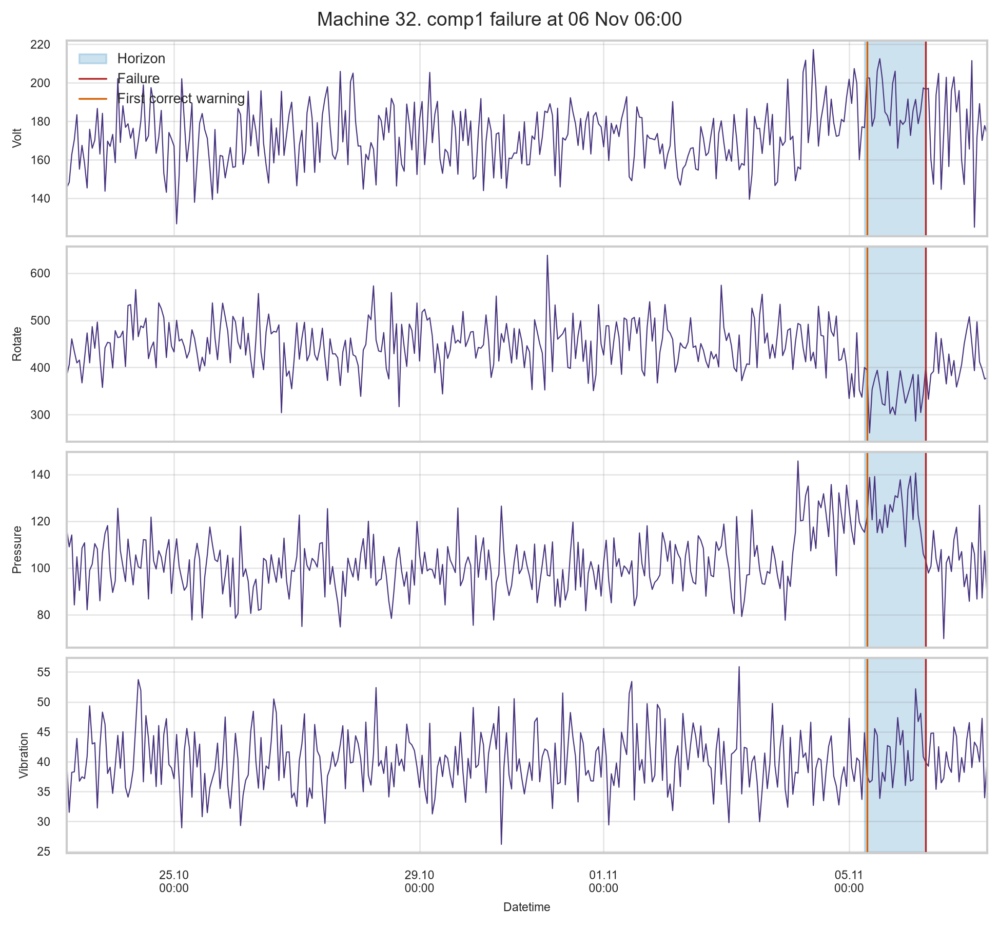

In [135]:
# plot telemetry for event which the most warnings were missed 
event = test_warning_coverage.sort_values('missed_warning_hours', ascending=False).iloc[0]
plot_telemetry_before_failure(telemetry, event, sensors, horizon=24, hours_before=336)

### Feature Importance

Compute SHAP values for a random sample of test observations and rank features by their mean absolute contributions across observations and class outputs. This analysis describes which features influence the fitted model most strongly, without establishing causal relationships

In [136]:
# calculate SHAP values for a sample of test observations
X_shap = X_test.sample(n=min(5000, len(X_test)), random_state=42)
shap_pool = Pool(X_shap, cat_features=cat_features)

shap_values = final_model.get_feature_importance(
    data=shap_pool,
    type='ShapValues',
    thread_count=4
)

# check SHAP dimensions: observations × classes × (features + base value)
expected_shape = (len(X_shap), len(final_model.classes_), X_shap.shape[1] + 1)
if shap_values.shape != expected_shape:
    raise ValueError(f'Unexpected SHAP shape: {shap_values.shape}')

# separate feature contributions from class-specific base values
# dimensions: observations × classes × (features + base value)
shap_contributions = shap_values[:, :, :-1]
base_values = shap_values[:, :, -1]

In [137]:
# average absolute contributions across observations, separately by class
importance_by_class = pd.DataFrame(
    np.abs(shap_contributions).mean(axis=0).T,
    index=X_shap.columns,
    columns=final_model.classes_
)

# average equally across class outputs to obtain an overall ranking
shap_importance = (
    importance_by_class
    .mean(axis=1)
    .rename('mean_abs_shap')
    .sort_values(ascending=False)
    .to_frame()
)

with pd.option_context('display.max_rows', None):
    display(shap_importance.head(20))

,mean_abs_shap
comp4_days_since_replacement,0.315345
comp2_days_since_replacement,0.285707
comp1_days_since_replacement,0.226744
comp3_days_since_replacement,0.217733
rotate_mean_24h,0.113845
volt_mean_24h,0.096116
model,0.086516
vibration_mean_24h,0.082727
vibration_mean_12h,0.065796
pressure_mean_3h,0.056361


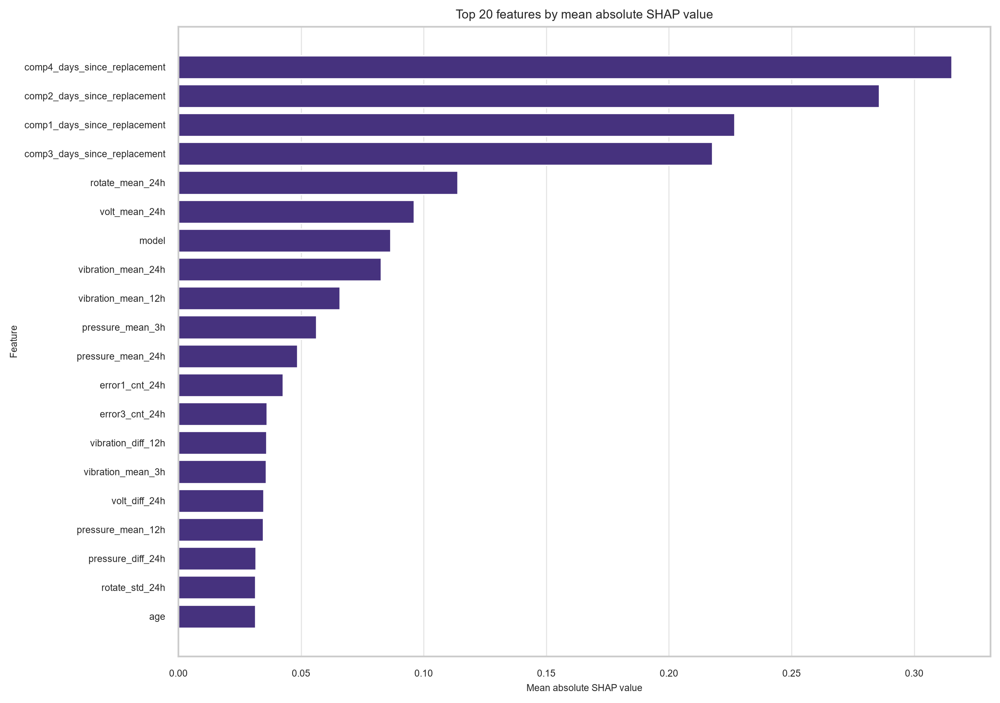

In [138]:
# plot the features with the largest mean absolute SHAP values
top_features = shap_importance.head(20).sort_values('mean_abs_shap')

fig, ax = plt.subplots(figsize=(10, 7), layout='constrained')
ax.barh(top_features.index, top_features['mean_abs_shap'])
ax.set(
    title='Top 20 features by mean absolute SHAP value',
    xlabel='Mean absolute SHAP value',
    ylabel='Feature'
)
ax.grid(False, axis='y')
ax.set_axisbelow(True)

plt.show()

Time since the last component replacement dominates the global SHAP ranking, with all four maintenance-history features occupying the top positions. The next most influential features include 24-hour sensor means, machine model. Error-count features have smaller average contributions but may remain important for individual predictions

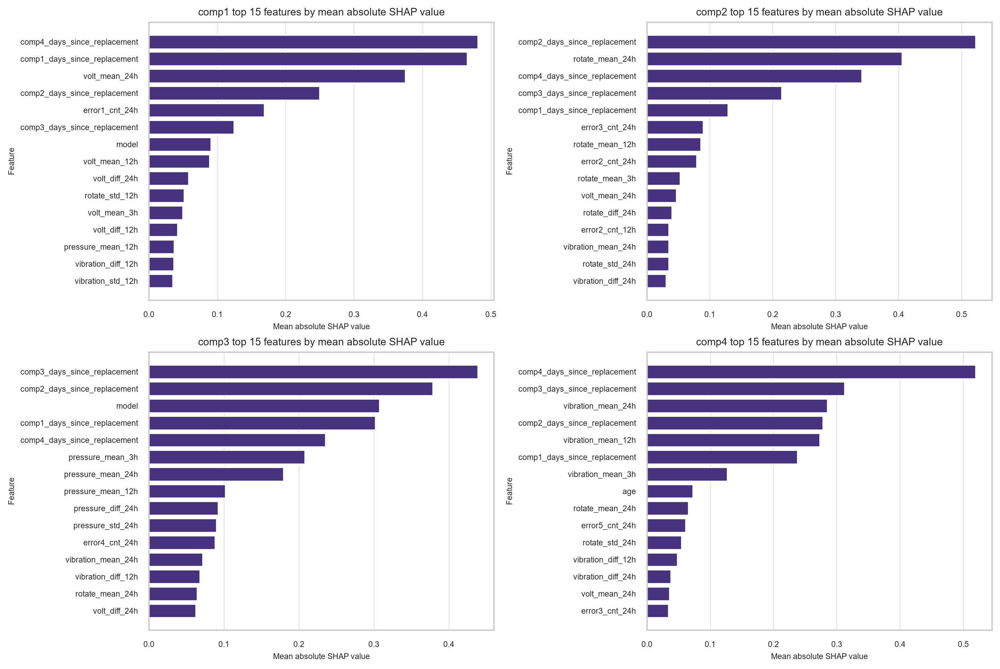

In [ ]:
# plot feature importance by class
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
for ax, comp in zip(axes.flat, COMPONENTS):
    
    top_features_by_class = (importance_by_class[comp]
        .sort_values(ascending=False)
        .head(15)
        .rename('mean_abs_shap')
        .to_frame()
    )

    ax.barh(top_features_by_class.index, top_features_by_class['mean_abs_shap'])
    ax.invert_yaxis()
    ax.set(
        title=f'{comp} top 15 features by mean absolute SHAP value',
        xlabel='Mean absolute SHAP value',
        ylabel='Feature'
    )
    ax.grid(False, axis='y')
    ax.set_axisbelow(True)

plt.show()

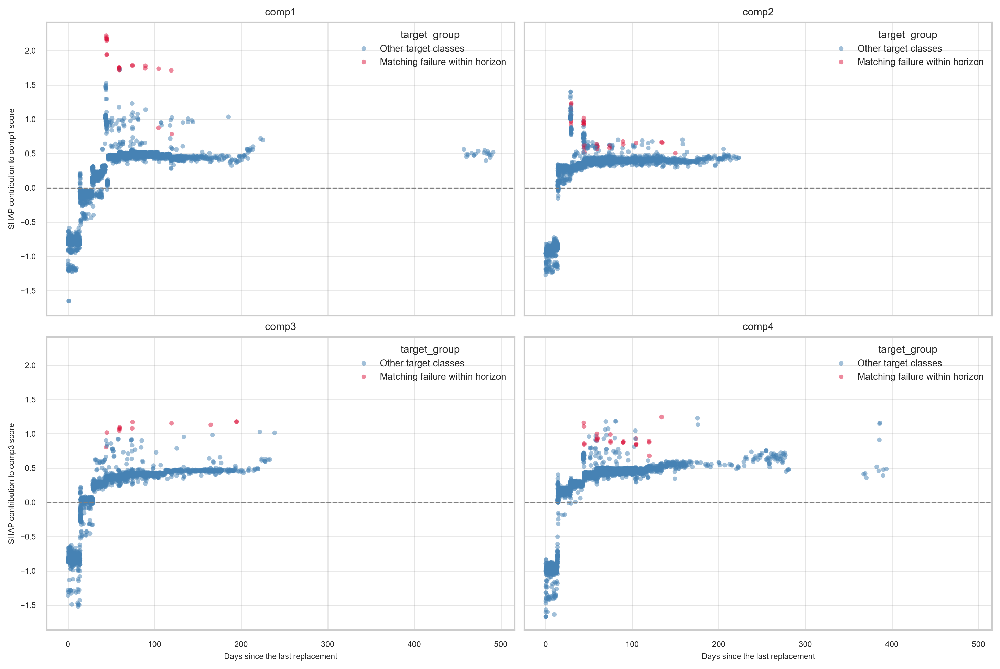

In [164]:
# examine how time since replacement contributes across all components
fig, axs = plt.subplots(2, 2, figsize=(12, 8),
    sharex=True,sharey=True, layout='constrained'
)

class_names = list(final_model.classes_)
sample_targets = y_test.loc[X_shap.index]

for ax, component in zip(axs.flat, COMPONENTS):
    feature = f'{component}_days_since_replacement'

    class_idx = class_names.index(component)
    feature_idx = X_shap.columns.get_loc(feature)

    plot_data = pd.DataFrame({
        'days_since_replacement': X_shap[feature].to_numpy(),
        'shap_value': shap_contributions[:, class_idx, feature_idx],
        'target_group': np.where(
            sample_targets.eq(component),
            'Matching failure within horizon',
            'Other target classes'
        )
    })

    sns.scatterplot(
        data=plot_data, x='days_since_replacement', y='shap_value',
        hue='target_group', 
        hue_order=['Other target classes', 'Matching failure within horizon'],
        palette={'Other target classes': 'steelblue', 'Matching failure within horizon': 'crimson'},
        alpha=0.5, s=16, linewidth=0, legend=True,
        ax=ax
    )
    ax.axhline(0, color='grey', linestyle='--', linewidth=1)

    ax.set(
        title=component,
        xlabel='Days since the last replacement',
        ylabel=f'SHAP contribution to {component} score'
    )

plt.show()

Across all four components, recent replacements generally contribute negatively to the corresponding raw failure-class score. Contributions subsequently become positive and largely plateau, with component-specific peaks and transitions. Variation at similar replacement ages is consistent with interactions with other features. These patterns describe model behaviour rather than a causal relationship between component age and failure